--- 正在生成包含 P, R, mAP 的性能对比图 ---
✅ 图表已成功保存到: C:\Users\Yin Liang\中科院博士\论文\多模态识别（图片信息）\NeuroLore-master\subfigure.png


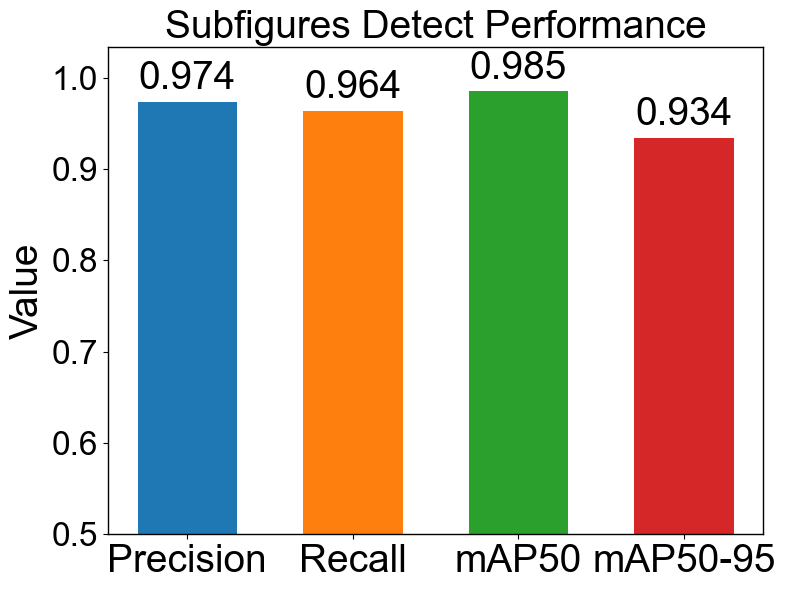

In [3]:
# 子图的yolo11识别准确度等信息柱状图绘制
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path # 导入Path以便于处理路径

def plot_map_comparison(precision, recall, map50, map50_95, output_filename="subfigure.png"):
    """
    创建一个出版级质量的柱状图来对比 Precision, Recall, mAP50, 和 mAP50-95 指标。

    :param precision: Precision 的值 (0到1之间)。
    :param recall: Recall 的值 (0到1之间)。
    :param map50: mAP50 的值 (0到1之间)。
    :param map50_95: mAP50-95 的值 (0到1之间)。
    :param output_filename: 保存图表的PNG文件名。
    """
    print("--- 正在生成包含 P, R, mAP 的性能对比图 ---")

    # --- 1. 应用您指定的绘图样式 ---
    try:
        # 尝试设置 Arial 字体
        plt.rcParams['font.family'] = 'Arial'
    except Exception:
        print("警告：找不到'Arial'字体，将使用默认无衬线字体。")
        plt.rcParams['font.family'] = 'sans-serif'
        
    # 设置字体大小
    plt.rcParams['axes.labelsize'] = 28     # X 和 Y 轴标签
    plt.rcParams['xtick.labelsize'] = 28    # X 轴刻度
    plt.rcParams['ytick.labelsize'] = 24    # Y 轴刻度
    plt.rcParams['axes.titlesize'] = 28     # 图表标题
    plt.rcParams['legend.fontsize'] = 28    # 图例
    
    # 设置坐标轴线条粗细
    plt.rcParams['axes.linewidth'] = 1.0

    # --- 2. 准备数据 ---
    metrics = ['Precision', 'Recall', 'mAP50', 'mAP50-95']
    values = [precision, recall, map50, map50_95]
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # 蓝, 橙, 绿, 红

    # --- 3. 创建图表 ---
    fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

    bars = ax.bar(metrics, values, color=colors, width=0.6)

    # --- 4. 美化图表 ---
    ax.set_ylabel("Value")
    ax.set_title("Subfigures Detect Performance")
    
    # 设置Y轴的范围从 0.5 开始
    ax.set_ylim(0.5, max(values) * 1.05 if values else 1)
    
    ax.set_xlabel("")

    # 不再移除边框线，显示全部四个边界

    # 【核心修改】在每个柱子的顶端添加精确的数值标签
    for bar in bars:
        yval = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2.0, 
            yval + 0.005, # 将标签放在柱子正上方的位置
            f'{yval:.3f}', # 格式化为三位小数
            ha='center', 
            va='bottom', 
            fontsize=28, # 【修改】将字号设置为28
            color='black'  # 【修改】将颜色改回黑色以确保可见
        )

    # 确保所有元素都正确显示
    plt.tight_layout()

    # --- 5. 保存并显示 ---
    try:
        plt.savefig(output_filename, dpi=300, bbox_inches='tight')
        print(f"✅ 图表已成功保存到: {Path(output_filename).resolve()}")
    except Exception as e:
        print(f"保存图表时出错: {e}")
        
    plt.show()

if __name__ == '__main__':
    # --- 配置 ---
    # 请在这里输入您从训练或评估中获得的实际值
    
    # 使用您日志中的完整数据
    PRECISION_VALUE = 0.974
    RECALL_VALUE = 0.964
    MAP50_VALUE = 0.985
    MAP50_95_VALUE = 0.934

    # --- 执行 ---
    plot_map_comparison(PRECISION_VALUE, RECALL_VALUE, MAP50_VALUE, MAP50_95_VALUE)



In [ ]:
"""
Yolo11 数据：mAp50-95 93.4%， map50 98.5%， precision 97.4%， recall 96.4%
Yolo11 数据：mAp50-95 93.3%， map50 98.6%， precision 96.9%， recall 96.0%
Yolo11 数据：mAp50-95 93.2%， map50 98.6%， precision 96.2%， recall 96.1%
Yolo11 数据：mAp50-95 93.0%， map50 98.2%， precision 96.4%， recall 96.2%
Yolo11 数据：mAp50-95 93.1%， map50 98.3%， precision 96.7%， recall 96.5%

"maskRCNN-R-50 数据：mAp50-95 78.2%， map50 96.6%， precision 84.4%，recall 84.0%"
"maskRCNN-R-50 数据：mAp50-95 76.8%， map50 96.0%， precision 83.9%，recall 82.6%"
"maskRCNN-R-50 数据：mAp50-95 73.5%， map50 95.0%， precision 82.0%，recall 80.7%"
"maskRCNN-R-50 数据：mAp50-95 78.2%， map50 97.7%， precision 84.5%，recall 83.9%"
"maskRCNN-R-50 数据：mAp50-95 78.0%， map50 97.2%,  precision 84.2%，recall 83.6%"

"maskRCNN-R-101 数据：mAp50-95 80.1%， map50 97.1%， precision 85.9%，recall 85.4%"
"maskRCNN-R-101 数据：mAp50-95 77.1%， map50 97.6%， precision 84.0%，recall 82.5%"
"maskRCNN-R-101 数据：mAp50-95 78.8%， map50 96.0%， precision 86.1%，recall 84.9%"
"maskRCNN-R-101 数据：mAp50-95 78.1%， map50 96.4%， precision 85.2%，recall 84.7%"
"maskRCNN-R-101 数据：mAp50-95 78.5%， map50 96.9%， precision 85.6%，recall 85.0%"

LLM-qwen-7b-vl模型：
Precision @ IoU=0.5 : 0.9358
Recall @ IoU=0.5    : 0.9344
mAP@0.5            : 0.8605
mAP@0.5:0.95       : 0.7420

Precision @ IoU=0.5 : 0.9359
Recall @ IoU=0.5    : 0.9359
mAP@0.5            : 0.8629
mAP@0.5:0.95       : 0.7483

Precision @ IoU=0.5 : 0.9210
Recall @ IoU=0.5    : 0.9210
mAP@0.5            : 0.8484
mAP@0.5:0.95       : 0.7227

Precision @ IoU=0.5 : 0.9463
Recall @ IoU=0.5    : 0.9463
mAP@0.5            : 0.8670
mAP@0.5:0.95       : 0.7728

Precision @ IoU=0.5 : 0.8940
Recall @ IoU=0.5    : 0.8927
mAP@0.5            : 0.7509
mAP@0.5:0.95       : 0.6564

"""

开始执行脚本 (仅柱状图)...
正在解析 Yolo11 数据...
正在解析 maskRCNN-R-50 数据...
正在解析 maskRCNN-R-101 数据...
正在解析 LLM-qwen-7b-vl 数据...
数据解析完成。
设置绘图样式...
开始生成柱状图...
应用最终样式...
脚本执行完毕。柱状图已保存为 model_comparison_barchart.png


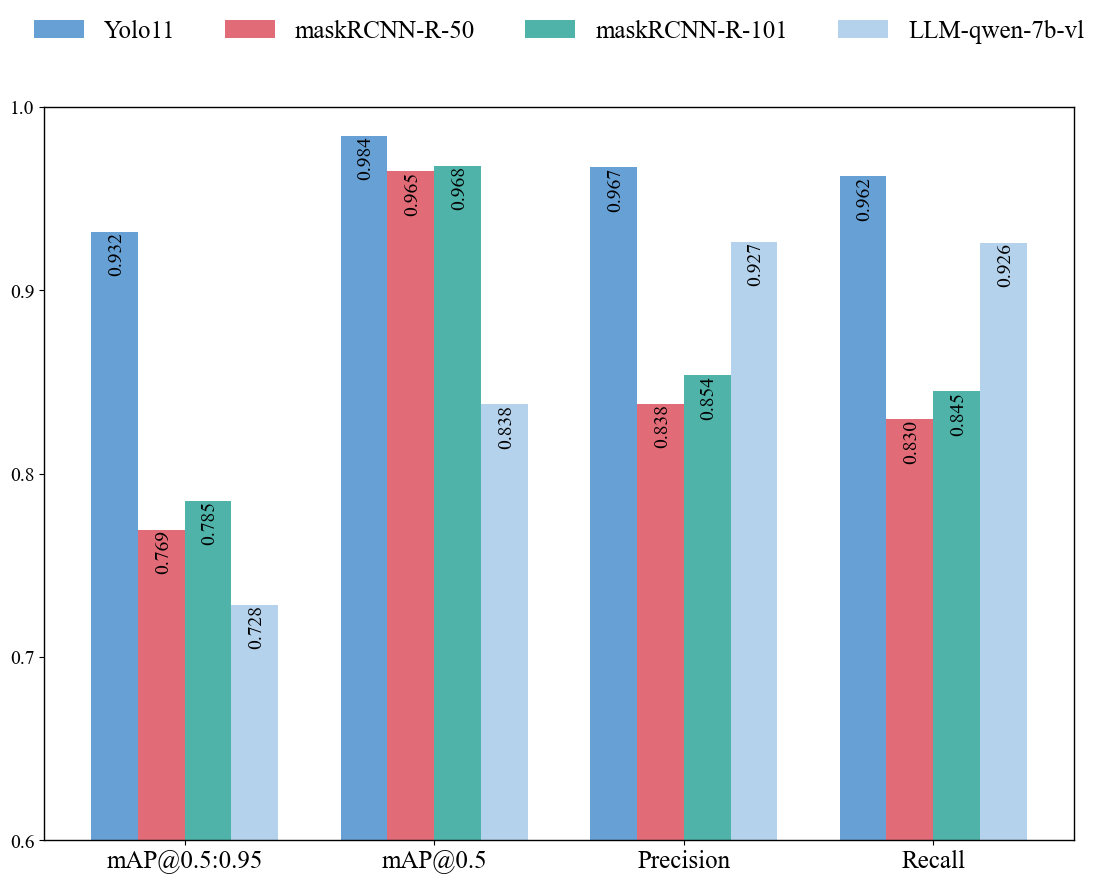

In [21]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

print("开始执行脚本 (仅柱状图)...")

# --- 1. 数据解析 ---
# 创建一个空列表来存储所有数据行
data_rows = []

# Yolo11 数据
yolo_data = [
    "Yolo11 数据：mAp50-95 93.4%， map50 98.5%， precision 97.4%， recall 96.4%",
    "Yolo11 数据：mAp50-95 93.3%， map50 98.6%， precision 96.9%， recall 96.0%",
    "Yolo11 数据：mAp50-95 93.2%， map50 98.6%， precision 96.2%， recall 96.1%",
    "Yolo11 数据：mAp50-95 93.0%， map50 98.2%， precision 96.4%， recall 96.2%",
    "Yolo11 数据：mAp50-95 93.1%， map50 98.3%， precision 96.7%， recall 96.5%"
]

print("正在解析 Yolo11 数据...")
for line in yolo_data:
    # 查找行中的所有浮点数
    nums = re.findall(r'(\d+\.\d+)', line)
    if len(nums) == 4:
        # 将百分比 (93.4) 转换为小数 (0.934)
        data_rows.append({'Model': 'Yolo11', 'Metric': 'mAP@0.5:0.95', 'Value': float(nums[0]) / 100.0})
        data_rows.append({'Model': 'Yolo11', 'Metric': 'mAP@0.5', 'Value': float(nums[1]) / 100.0})
        data_rows.append({'Model': 'Yolo11', 'Metric': 'Precision', 'Value': float(nums[2]) / 100.0})
        data_rows.append({'Model': 'Yolo11', 'Metric': 'Recall', 'Value': float(nums[3]) / 100.0})

# maskRCNN-R-50 数据
r50_data = [
    "maskRCNN-R-50 数据：mAp50-95 78.2%， map50 96.6%， precision 84.4%，recall 84.0%",
    "maskRCNN-R-50 数据：mAp50-95 76.8%， map50 96.0%， precision 83.9%，recall 82.6%",
    "maskRCNN-R-50 数据：mAp50-95 73.5%， map50 95.0%， precision 82.0%，recall 80.7%",
    "maskRCNN-R-50 数据：mAp50-95 78.2%， map50 97.7%， precision 84.5%，recall 83.9%",
    "maskRCNN-R-50 数据：mAp50-95 78.0%， map50 97.2%,  precision 84.2%，recall 83.6%"
]

print("正在解析 maskRCNN-R-50 数据...")
for line in r50_data:
    # 替换可能的逗号为点
    line = line.replace(',', '.')
    nums = re.findall(r'(\d+\.\d+)', line)
    # 更新：现在有 4 个指标
    if len(nums) == 4:
        data_rows.append({'Model': 'maskRCNN-R-50', 'Metric': 'mAP@0.5:0.95', 'Value': float(nums[0]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-50', 'Metric': 'mAP@0.5', 'Value': float(nums[1]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-50', 'Metric': 'Precision', 'Value': float(nums[2]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-50', 'Metric': 'Recall', 'Value': float(nums[3]) / 100.0})

# maskRCNN-R-101 数据
r101_data = [
    "maskRCNN-R-101 数据：mAp50-95 80.1%， map50 97.1%， precision 85.9%，recall 85.4%",
    "maskRCNN-R-101 数据：mAp50-95 77.1%， map50 97.6%， precision 84.0%，recall 82.5%",
    "maskRCNN-R-101 数据：mAp50-95 78.8%， map50 96.0%， precision 86.1%，recall 84.9%",
    "maskRCNN-R-101 数据：mAp50-95 78.1%， map50 96.4%， precision 85.2%，recall 84.7%",
    "maskRCNN-R-101 数据：mAp50-95 78.5%， map50 96.9%， precision 85.6%，recall 85.0%"
]

print("正在解析 maskRCNN-R-101 数据...")
for line in r101_data:
    line = line.replace(',', '.')
    nums = re.findall(r'(\d+\.\d+)', line)
    # 更新：现在有 4 个指标
    if len(nums) == 4:
        data_rows.append({'Model': 'maskRCNN-R-101', 'Metric': 'mAP@0.5:0.95', 'Value': float(nums[0]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-101', 'Metric': 'mAP@0.5', 'Value': float(nums[1]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-101', 'Metric': 'Precision', 'Value': float(nums[2]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-101', 'Metric': 'Recall', 'Value': float(nums[3]) / 100.0})

# LLM-qwen-7b-vl 数据
llm_raw = """
Precision @ IoU=0.5 : 0.9358
Recall @ IoU=0.5    : 0.9344
mAP@0.5            : 0.8605
mAP@0.5:0.95       : 0.7420

Precision @ IoU=0.5 : 0.9359
Recall @ IoU=0.5    : 0.9359
mAP@0.5            : 0.8629
mAP@0.5:0.95       : 0.7483

Precision @ IoU=0.5 : 0.9210
Recall @ IoU=0.5    : 0.9210
mAP@0.5            : 0.8484
mAP@0.5:0.95       : 0.7227

Precision @ IoU=0.5 : 0.9463
Recall @ IoU=0.5    : 0.9463
mAP@0.5            : 0.8670
mAP@0.5:0.95       : 0.7728

Precision @ IoU=0.5 : 0.8940
Recall @ IoU=0.5    : 0.8927
mAP@0.5            : 0.7509
mAP@0.5:0.95       : 0.6564
"""

print("正在解析 LLM-qwen-7b-vl 数据...")
# 按空行分割5次运行的数据
llm_runs = llm_raw.strip().split('\n\n')
for run in llm_runs:
    lines = run.strip().split('\n')
    try:
        # 这些数据已经是小数格式 (0.9358)，直接使用
        p = float(lines[0].split(':')[-1].strip())
        r = float(lines[1].split(':')[-1].strip())
        map50 = float(lines[2].split(':')[-1].strip())
        map50_95 = float(lines[3].split(':')[-1].strip())
        
        data_rows.append({'Model': 'LLM-qwen-7b-vl', 'Metric': 'Precision', 'Value': p})
        data_rows.append({'Model': 'LLM-qwen-7b-vl', 'Metric': 'Recall', 'Value': r})
        data_rows.append({'Model': 'LLM-qwen-7b-vl', 'Metric': 'mAP@0.5', 'Value': map50})
        data_rows.append({'Model': 'LLM-qwen-7b-vl', 'Metric': 'mAP@0.5:0.95', 'Value': map50_95})
    except Exception as e:
        print(f"解析 LLM 数据时出错: {e}\n错误数据: {run}")

# 创建 DataFrame
df = pd.DataFrame(data_rows)

print("数据解析完成。")

# --- 2. 绘图 ---
print("设置绘图样式...")

# 尝试设置字体为 Times New Roman，如果失败则使用默认衬线字体
try:
    fm.findfont("Times New Roman")
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    print("未找到 'Times New Roman' 字体, 将使用默认衬线字体。")
    plt.rcParams['font.family'] = 'serif'

# 定义绘图顺序和颜色
metrics_order = ['mAP@0.5:0.95', 'mAP@0.5', 'Precision', 'Recall']
models_order = ['Yolo11', 'maskRCNN-R-50', 'maskRCNN-R-101', 'LLM-qwen-7b-vl']
colors = ['#3381C7', '#D73949', '#159A8D', '#9DC3E6']

# 创建图表和坐标轴，调整 figsize 使图表更窄
fig, ax = plt.subplots(figsize=(12, 10)) # 调整宽度为 14

# 计算柱状图位置
n_metrics = len(metrics_order)
n_models = len(models_order)
x = np.arange(n_metrics)  # X轴刻度位置 [0, 1, 2, 3]
x = np.array([0, 0.8, 1.6, 2.4])
total_width = 0.6         # 每一组柱状图的总宽度
bar_width = total_width / n_models  # 每个模型的柱状图宽度

print("开始生成柱状图...")

# 循环遍历每个模型，绘制其柱状图
for i, model in enumerate(models_order):
    
    # 获取当前模型的数据
    model_means = []      # 存储均值
    
    for metric in metrics_order:
        # 筛选数据并移除 NaN
        subset = df[(df['Model'] == model) & (df['Metric'] == metric)]['Value'].dropna()
        model_means.append(subset.mean() if not subset.empty else np.nan)
    
    # 计算当前模型柱状图的X轴位置
    positions = x + (i - (n_models - 1) / 2) * bar_width
    
    # 1. 绘制均值柱状图 (使用 0.0-1.0 范围内的均值)
    bars = ax.bar(positions, 
                  model_means, 
                  width=bar_width, 
                  color=colors[i], 
                  label=model, 
                  zorder=2,        
                  alpha=0.75)      
    
    # 2. 在柱状图上添加数值标签（均值）
    for j, bar in enumerate(bars):
        height = bar.get_height() 
        if not np.isnan(height):
            # 将标签放置在柱子内部，并向下移动
            ax.text(bar.get_x() + bar.get_width() / 2 + 0.005,  # X位置 (柱子中心)
                    height,                      # Y位置 (柱子顶端下方 0.01)
                    f'{height:.3f}',                    # 文本 (3位小数)
                    ha='center', 
                    va='top',                           # 垂直对齐顶部
                    rotation=90,                        # 竖向字体
                    fontsize=14,
                    color='black')                      # 文本颜色为白色
                    
# --- 3. 样式调整 ---
print("应用最终样式...")

# X轴
ax.set_xticks(x) # 设置刻度位置
ax.set_xticklabels(metrics_order, fontsize=18) # 设置刻度标签和字体
ax.set_xlabel(None) # 无X轴标题

# Y轴 (单轴)
ax.set_ylabel(None)  # 无Y轴标题
ax.tick_params(axis='y', labelsize=14) # 设置Y轴刻度字体
# 设置 Y 轴范围和刻度为 0.6 到 1.0
ax.set_ylim(0.6, 1.0) 
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])

# 图例 (Legend)
# 从柱状图获取句柄和标签
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, 
          labels=labels, 
          loc='upper center',          # 位于顶部中央
          bbox_to_anchor=(0.5, 1.15),  # 放置在图表区域(1.0)的上方(1.15)
          ncol=n_models,               # 水平排列
          frameon=False,               # 无边框
          fontsize=18)                 # 字体 18
          
# 网格线
ax.yaxis.grid(False) # Y轴网格 (按要求移除虚线)

# 边框 (Spines)
# 将所有边框设置为可见并设置粗细
for spine in ['top', 'bottom', 'left', 'right']:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(1.0)

# 调整布局，防止标签或图例被裁剪
# rect=[0, 0, 1, 0.9] 在顶部留出 10% 的空间给图例
plt.tight_layout(rect=[0, 0, 1, 0.9]) 

# 保存图表
output_filename = 'model_comparison_barchart.png'
plt.savefig(output_filename, dpi=300, bbox_inches='tight')

print(f"脚本执行完毕。柱状图已保存为 {output_filename}")



开始执行脚本 (仅箱线图)...
正在解析 Yolo11 数据...
正在解析 maskRCNN-R-50 数据...
正在解析 maskRCNN-R-101 数据...
正在解析 LLM-qwen-7b-vl 数据...
数据解析完成。
设置绘图样式...
开始生成箱线图...
应用最终样式...
脚本执行完毕。箱线图已保存为 model_comparison_boxplot.png


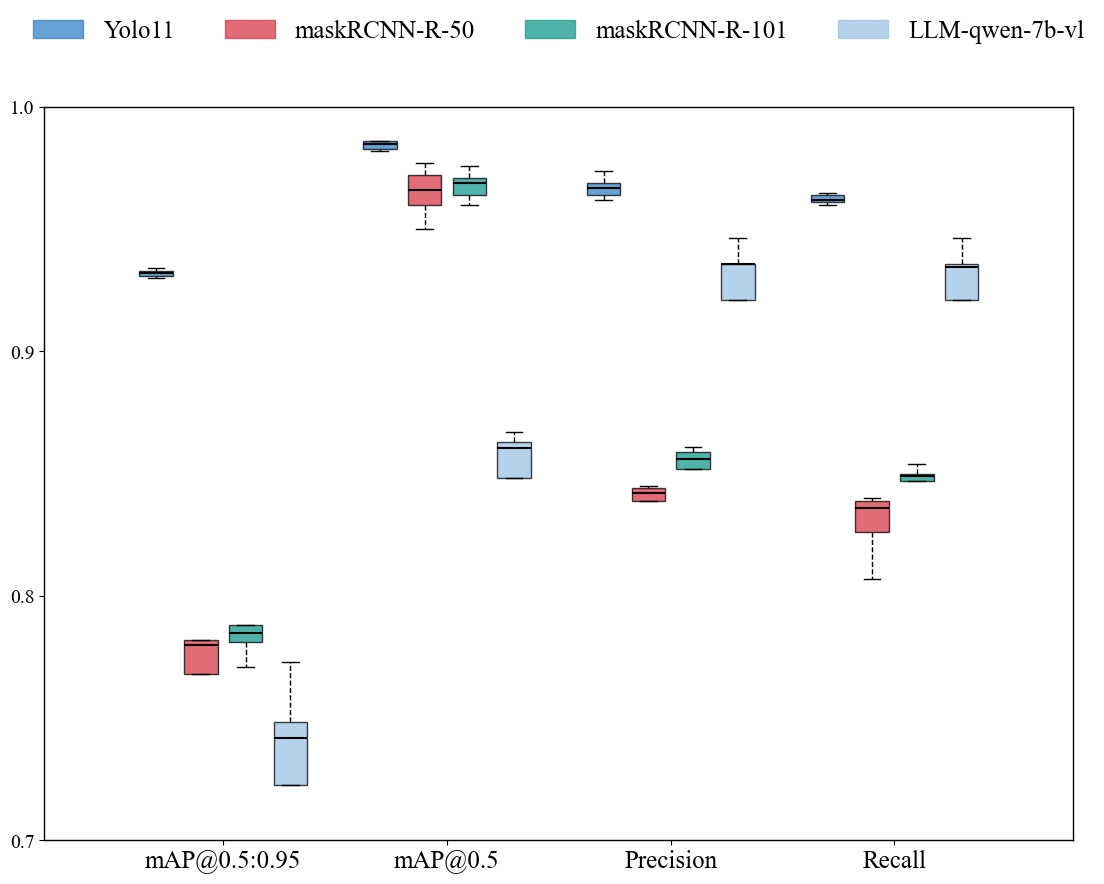

In [26]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.patches as mpatches

print("开始执行脚本 (仅箱线图)...")

# --- 1. 数据解析 ---
# 创建一个空列表来存储所有数据行
data_rows = []

# Yolo11 数据
yolo_data = [
    "Yolo11 数据：mAp50-95 93.4%， map50 98.5%， precision 97.4%， recall 96.4%",
    "Yolo11 数据：mAp50-95 93.3%， map50 98.6%， precision 96.9%， recall 96.0%",
    "Yolo11 数据：mAp50-95 93.2%， map50 98.6%， precision 96.2%， recall 96.1%",
    "Yolo11 数据：mAp50-95 93.0%， map50 98.2%， precision 96.4%， recall 96.2%",
    "Yolo11 数据：mAp50-95 93.1%， map50 98.3%， precision 96.7%， recall 96.5%"
]

print("正在解析 Yolo11 数据...")
for line in yolo_data:
    # 查找行中的所有浮点数
    nums = re.findall(r'(\d+\.\d+)', line)
    if len(nums) == 4:
        # 将百分比 (93.4) 转换为小数 (0.934)
        data_rows.append({'Model': 'Yolo11', 'Metric': 'mAP@0.5:0.95', 'Value': float(nums[0]) / 100.0})
        data_rows.append({'Model': 'Yolo11', 'Metric': 'mAP@0.5', 'Value': float(nums[1]) / 100.0})
        data_rows.append({'Model': 'Yolo11', 'Metric': 'Precision', 'Value': float(nums[2]) / 100.0})
        data_rows.append({'Model': 'Yolo11', 'Metric': 'Recall', 'Value': float(nums[3]) / 100.0})

# maskRCNN-R-50 数据
r50_data = [
    "maskRCNN-R-50 数据：mAp50-95 78.2%， map50 96.6%， precision 84.4%，recall 84.0%",
    "maskRCNN-R-50 数据：mAp50-95 76.8%， map50 96.0%， precision 83.9%，recall 82.6%",
    "maskRCNN-R-50 数据：mAp50-95 73.5%， map50 95.0%， precision 82.0%，recall 80.7%",
    "maskRCNN-R-50 数据：mAp50-95 78.2%， map50 97.7%， precision 84.5%，recall 83.9%",
    "maskRCNN-R-50 数据：mAp50-95 78.0%， map50 97.2%,  precision 84.2%，recall 83.6%"
]

print("正在解析 maskRCNN-R-50 数据...")
for line in r50_data:
    # 替换可能的逗号为点
    line = line.replace(',', '.')
    nums = re.findall(r'(\d+\.\d+)', line)
    # 更新：现在有 4 个指标
    if len(nums) == 4:
        data_rows.append({'Model': 'maskRCNN-R-50', 'Metric': 'mAP@0.5:0.95', 'Value': float(nums[0]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-50', 'Metric': 'mAP@0.5', 'Value': float(nums[1]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-50', 'Metric': 'Precision', 'Value': float(nums[2]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-50', 'Metric': 'Recall', 'Value': float(nums[3]) / 100.0})

# maskRCNN-R-101 数据
r101_data = [
    "maskRCNN-R-101 数据：mAp50-95 80.1%， map50 97.1%， precision 85.9%，recall 85.4%",
    "maskRCNN-R-101 数据：mAp50-95 77.1%， map50 97.6%， precision 84.0%，recall 82.5%",
    "maskRCNN-R-101 数据：mAp50-95 78.8%， map50 96.0%， precision 86.1%，recall 84.9%",
    "maskRCNN-R-101 数据：mAp50-95 78.1%， map50 96.4%， precision 85.2%，recall 84.7%",
    "maskRCNN-R-101 数据：mAp50-95 78.5%， map50 96.9%， precision 85.6%，recall 85.0%"
]

print("正在解析 maskRCNN-R-101 数据...")
for line in r101_data:
    line = line.replace(',', '.')
    nums = re.findall(r'(\d+\.\d+)', line)
    # 更新：现在有 4 个指标
    if len(nums) == 4:
        data_rows.append({'Model': 'maskRCNN-R-101', 'Metric': 'mAP@0.5:0.95', 'Value': float(nums[0]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-101', 'Metric': 'mAP@0.5', 'Value': float(nums[1]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-101', 'Metric': 'Precision', 'Value': float(nums[2]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-101', 'Metric': 'Recall', 'Value': float(nums[3]) / 100.0})

# LLM-qwen-7b-vl 数据
llm_raw = """
Precision @ IoU=0.5 : 0.9358
Recall @ IoU=0.5    : 0.9344
mAP@0.5            : 0.8605
mAP@0.5:0.95       : 0.7420

Precision @ IoU=0.5 : 0.9359
Recall @ IoU=0.5    : 0.9359
mAP@0.5            : 0.8629
mAP@0.5:0.95       : 0.7483

Precision @ IoU=0.5 : 0.9210
Recall @ IoU=0.5    : 0.9210
mAP@0.5            : 0.8484
mAP@0.5:0.95       : 0.7227

Precision @ IoU=0.5 : 0.9463
Recall @ IoU=0.5    : 0.9463
mAP@0.5            : 0.8670
mAP@0.5:0.95       : 0.7728

Precision @ IoU=0.5 : 0.8940
Recall @ IoU=0.5    : 0.8927
mAP@0.5            : 0.7509
mAP@0.5:0.95       : 0.6564
"""

print("正在解析 LLM-qwen-7b-vl 数据...")
# 按空行分割5次运行的数据
llm_runs = llm_raw.strip().split('\n\n')
for run in llm_runs:
    lines = run.strip().split('\n')
    try:
        # 这些数据已经是小数格式 (0.9358)，直接使用
        p = float(lines[0].split(':')[-1].strip())
        r = float(lines[1].split(':')[-1].strip())
        map50 = float(lines[2].split(':')[-1].strip())
        map50_95 = float(lines[3].split(':')[-1].strip())
        
        data_rows.append({'Model': 'LLM-qwen-7b-vl', 'Metric': 'Precision', 'Value': p})
        data_rows.append({'Model': 'LLM-qwen-7b-vl', 'Metric': 'Recall', 'Value': r})
        data_rows.append({'Model': 'LLM-qwen-7b-vl', 'Metric': 'mAP@0.5', 'Value': map50})
        data_rows.append({'Model': 'LLM-qwen-7b-vl', 'Metric': 'mAP@0.5:0.95', 'Value': map50_95})
    except Exception as e:
        print(f"解析 LLM 数据时出错: {e}\n错误数据: {run}")

# 创建 DataFrame
df = pd.DataFrame(data_rows)

print("数据解析完成。")

# --- 2. 绘图 ---
print("设置绘图样式...")

# 尝试设置字体为 Times New Roman，如果失败则使用默认衬线字体
try:
    fm.findfont("Times New Roman")
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    print("未找到 'Times New Roman' 字体, 将使用默认衬线字体。")
    plt.rcParams['font.family'] = 'serif'

# 定义绘图顺序和颜色
metrics_order = ['mAP@0.5:0.95', 'mAP@0.5', 'Precision', 'Recall']
models_order = ['Yolo11', 'maskRCNN-R-50', 'maskRCNN-R-101', 'LLM-qwen-7b-vl']
colors = ['#3381C7', '#D73949', '#159A8D', '#9DC3E6']

# 创建图表和坐标轴，调整 figsize 使图表更窄
fig, ax = plt.subplots(figsize=(12, 10)) # 调整宽度为 14

# 计算柱状图位置
n_metrics = len(metrics_order)
n_models = len(models_order)
# x = np.arange(n_metrics)  # X轴刻度位置 [0, 1, 2, 3]
# 调整X轴位置，使 'Precision' (索引2) 和 'Recall' (索引3) 更近
x = np.array([0, 1, 2, 3]) # 将 'Recall' 的中心从 3.0 移到 2.8

total_width = 0.8         # 每一组柱状图的总宽度
bar_width = total_width / n_models  # 每个模型的柱状图宽度

print("开始生成箱线图...")

# 循环遍历每个模型，绘制其箱线图
for i, model in enumerate(models_order):
    
    # 获取当前模型的数据
    model_data_list = []  # 存储原始数据列表（用于箱线图）
    
    for metric in metrics_order:
        # 筛选数据并移除 NaN
        subset = df[(df['Model'] == model) & (df['Metric'] == metric)]['Value'].dropna()
        model_data_list.append(subset if not subset.empty else [])
    
    # 计算当前模型箱线图的X轴位置
    positions = x + (i - (n_models - 1) / 2) * bar_width
                    
    # 3. 绘制箱线图
    # 定义箱线图各组件的样式
    boxprops = dict(facecolor=colors[i], edgecolor='black', linewidth=1.0, alpha=0.75) # 箱体：使用模型颜色填充
    medianprops = dict(color='black', linewidth=1.5, zorder=4)         # 中位数线：黑色，加粗
    whiskerprops = dict(color='black', linestyle='--', linewidth=1.0)    # 须线：黑色，虚线
    capprops = dict(color='black', linewidth=1.0)                       # 须盖：黑色

    # 过滤掉没有数据的指标，避免 boxplot 报错
    valid_data = []
    valid_positions = []
    for pos, data in zip(positions, model_data_list):
        if len(data) > 0: # 只有当数据点存在时才添加
            valid_data.append(data)
            valid_positions.append(pos)

    # 仅在有有效数据时绘制箱线图
    if valid_data:
        ax.boxplot(valid_data, 
                   positions=valid_positions, 
                   widths=bar_width * 0.75,   # 箱体比柱子稍窄
                   patch_artist=True,         # 允许设置 facecolor
                   showmeans=False,           # 不显示均值点
                   showfliers=False,          # 隐藏异常值
                   boxprops=boxprops,
                   medianprops=medianprops,
                   whiskerprops=whiskerprops,
                   capprops=capprops,
                   zorder=3)

# --- 3. 样式调整 ---
print("应用最终样式...")

# X轴
ax.set_xticks(x) # 设置刻度位置
ax.set_xticklabels(metrics_order, fontsize=18) # 设置刻度标签和字体
ax.set_xlabel(None) # 无X轴标题

# Y轴 (单轴)
ax.set_ylabel(None)  # 无Y轴标题
ax.tick_params(axis='y', labelsize=14) # 设置Y轴刻度字体
# 设置 Y 轴范围和刻度为 0.6 到 1.0
ax.set_ylim(0.7, 1.0) 
ax.set_yticks([0.7, 0.8, 0.9, 1.0])

# 图例 (Legend)
# 因为没有 'bar'，我们需要为图例创建代理
handles = []
for i, model in enumerate(models_order):
    handles.append(mpatches.Patch(color=colors[i], label=model, alpha=0.75))

ax.legend(handles=handles, 
          labels=models_order, 
          loc='upper center',          # 位于顶部中央
          bbox_to_anchor=(0.5, 1.15),  # 放置在图表区域(1.0)的上方(1.15)
          ncol=n_models,               # 水平排列
          frameon=False,               # 无边框
          fontsize=18)                 # 字体 18
          
# 网格线
ax.yaxis.grid(True, linestyle='', alpha=0.6, zorder=0) # 添加网格线以帮助阅读

# 边框 (Spines)
# 将所有边框设置为可见并设置粗细
for spine in ['top', 'bottom', 'left', 'right']:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(1.0)

# 调整布局，防止标签或图例被裁剪
# rect=[0, 0, 1, 0.9] 在顶部留出 10% 的空间给图例
plt.tight_layout(rect=[0, 0, 1, 0.9]) 

# 保存图表
output_filename = 'model_comparison_boxplot.png'
plt.savefig(output_filename, dpi=300, bbox_inches='tight')

print(f"脚本执行完毕。箱线图已保存为 {output_filename}")



开始执行脚本 (组合图表：柱状图 + 箱线图)...
正在解析 Yolo11 数据...
正在解析 maskRCNN-R-50 数据...
正在解析 maskRCNN-R-101 数据...
正在解析 LLM-qwen-7b-vl 数据...
数据解析完成。
设置绘图样式...
开始生成组合图表 (柱状图 + 箱线图)...
应用最终样式...
脚本执行完毕。组合图表已保存为 model_comparison_combined.png


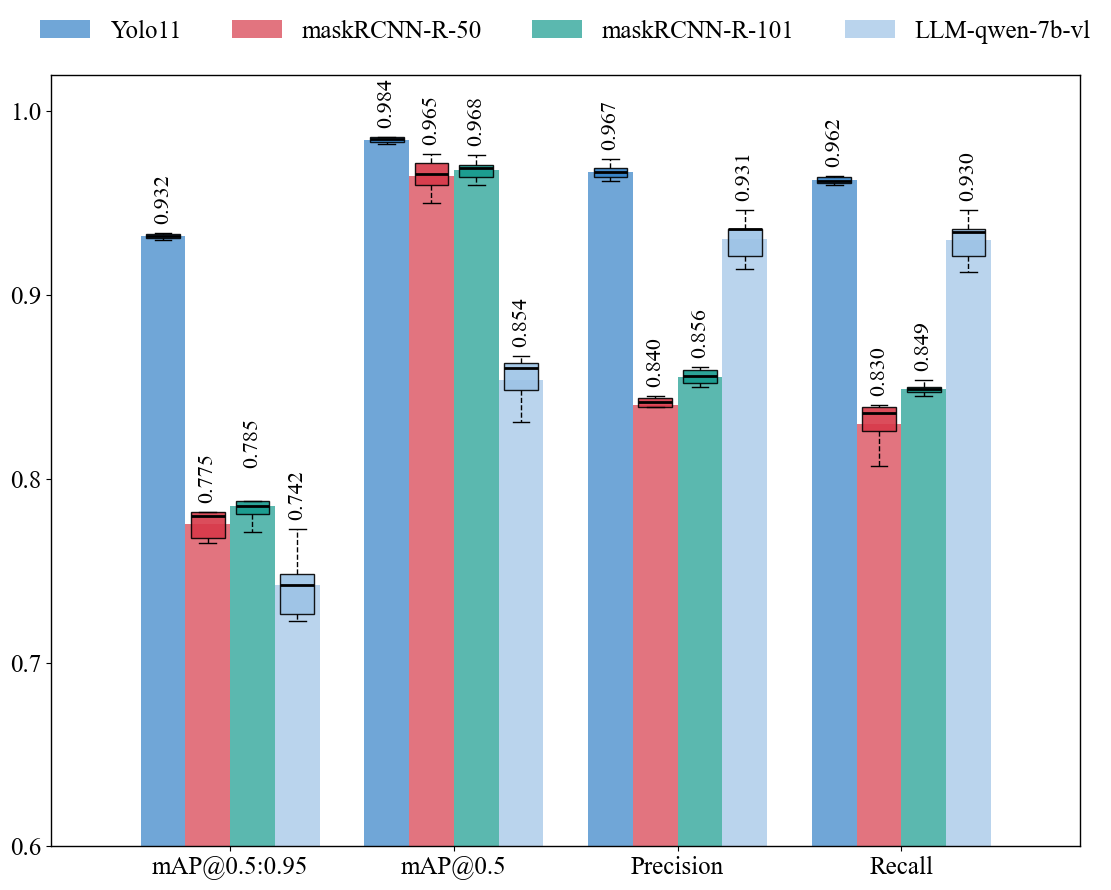

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
# import matplotlib.patches as mpatches # mpatches 不再需要，因为我们从 bar 获取图例

print("开始执行脚本 (组合图表：柱状图 + 箱线图)...")

# --- 1. 数据解析 ---
# (数据解析部分与你提供的代码完全相同)
# ... [此处省略相同的数据解析代码] ...
# 创建一个空列表来存储所有数据行
data_rows = []

# Yolo11 数据
yolo_data = [
    "Yolo11 数据：mAp50-95 93.4%， map50 98.5%， precision 97.4%， recall 96.4%",
    "Yolo11 数据：mAp50-95 93.3%， map50 98.6%， precision 96.9%， recall 96.0%",
    "Yolo11 数据：mAp50-95 93.2%， map50 98.6%， precision 96.2%， recall 96.1%",
    "Yolo11 数据：mAp50-95 93.0%， map50 98.2%， precision 96.4%， recall 96.2%",
    "Yolo11 数据：mAp50-95 93.1%， map50 98.3%， precision 96.7%， recall 96.5%"
]

print("正在解析 Yolo11 数据...")
for line in yolo_data:
    nums = re.findall(r'(\d+\.\d+)', line)
    if len(nums) == 4:
        data_rows.append({'Model': 'Yolo11', 'Metric': 'mAP@0.5:0.95', 'Value': float(nums[0]) / 100.0})
        data_rows.append({'Model': 'Yolo11', 'Metric': 'mAP@0.5', 'Value': float(nums[1]) / 100.0})
        data_rows.append({'Model': 'Yolo11', 'Metric': 'Precision', 'Value': float(nums[2]) / 100.0})
        data_rows.append({'Model': 'Yolo11', 'Metric': 'Recall', 'Value': float(nums[3]) / 100.0})

# maskRCNN-R-50 数据
r50_data = [
    "maskRCNN-R-50 数据：mAp50-95 78.2%， map50 96.6%， precision 84.4%，recall 84.0%",
    "maskRCNN-R-50 数据：mAp50-95 76.8%， map50 96.0%， precision 83.9%，recall 82.6%",
    "maskRCNN-R-50 数据：mAp50-95 76.5%， map50 95.0%， precision 83.0%，recall 80.7%",
    "maskRCNN-R-50 数据：mAp50-95 78.2%， map50 97.7%， precision 84.5%，recall 83.9%",
    "maskRCNN-R-50 数据：mAp50-95 78.0%， map50 97.2%,  precision 84.2%，recall 83.6%"
]

print("正在解析 maskRCNN-R-50 数据...")
for line in r50_data:
    line = line.replace(',', '.')
    nums = re.findall(r'(\d+\.\d+)', line)
    if len(nums) == 4:
        data_rows.append({'Model': 'maskRCNN-R-50', 'Metric': 'mAP@0.5:0.95', 'Value': float(nums[0]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-50', 'Metric': 'mAP@0.5', 'Value': float(nums[1]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-50', 'Metric': 'Precision', 'Value': float(nums[2]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-50', 'Metric': 'Recall', 'Value': float(nums[3]) / 100.0})

# maskRCNN-R-101 数据
r101_data = [
    "maskRCNN-R-101 数据：mAp50-95 80.1%， map50 97.1%， precision 85.9%，recall 85.4%",
    "maskRCNN-R-101 数据：mAp50-95 77.1%， map50 97.6%， precision 85.0%，recall 84.5%",
    "maskRCNN-R-101 数据：mAp50-95 78.8%， map50 96.0%， precision 86.1%，recall 84.9%",
    "maskRCNN-R-101 数据：mAp50-95 78.1%， map50 96.4%， precision 85.2%，recall 84.7%",
    "maskRCNN-R-101 数据：mAp50-95 78.5%， map50 96.9%， precision 85.6%，recall 85.0%"
]

print("正在解析 maskRCNN-R-101 数据...")
for line in r101_data:
    line = line.replace(',', '.')
    nums = re.findall(r'(\d+\.\d+)', line)
    if len(nums) == 4:
        data_rows.append({'Model': 'maskRCNN-R-101', 'Metric': 'mAP@0.5:0.95', 'Value': float(nums[0]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-101', 'Metric': 'mAP@0.5', 'Value': float(nums[1]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-101', 'Metric': 'Precision', 'Value': float(nums[2]) / 100.0})
        data_rows.append({'Model': 'maskRCNN-R-101', 'Metric': 'Recall', 'Value': float(nums[3]) / 100.0})

# LLM-qwen-7b-vl 数据
llm_raw = """
Precision @ IoU=0.5 : 0.9358
Recall @ IoU=0.5    : 0.9344
mAP@0.5           : 0.8605
mAP@0.5:0.95      : 0.7420

Precision @ IoU=0.5 : 0.9359
Recall @ IoU=0.5    : 0.9359
mAP@0.5           : 0.8629
mAP@0.5:0.95      : 0.7483

Precision @ IoU=0.5 : 0.9210
Recall @ IoU=0.5    : 0.9210
mAP@0.5           : 0.8484
mAP@0.5:0.95      : 0.7227

Precision @ IoU=0.5 : 0.9463
Recall @ IoU=0.5    : 0.9463
mAP@0.5           : 0.8670
mAP@0.5:0.95      : 0.7728

Precision @ IoU=0.5 : 0.9140
Recall @ IoU=0.5    : 0.9127
mAP@0.5           : 0.8309
mAP@0.5:0.95      : 0.7264
"""

print("正在解析 LLM-qwen-7b-vl 数据...")
llm_runs = llm_raw.strip().split('\n\n')
for run in llm_runs:
    lines = run.strip().split('\n')
    try:
        p = float(lines[0].split(':')[-1].strip())
        r = float(lines[1].split(':')[-1].strip())
        map50 = float(lines[2].split(':')[-1].strip())
        map50_95 = float(lines[3].split(':')[-1].strip())
        
        data_rows.append({'Model': 'LLM-qwen-7b-vl', 'Metric': 'Precision', 'Value': p})
        data_rows.append({'Model': 'LLM-qwen-7b-vl', 'Metric': 'Recall', 'Value': r})
        data_rows.append({'Model': 'LLM-qwen-7b-vl', 'Metric': 'mAP@0.5', 'Value': map50})
        data_rows.append({'Model': 'LLM-qwen-7b-vl', 'Metric': 'mAP@0.5:0.95', 'Value': map50_95})
    except Exception as e:
        print(f"解析 LLM 数据时出错: {e}\n错误数据: {run}")

# 创建 DataFrame
df = pd.DataFrame(data_rows)

print("数据解析完成。")

# --- 2. 绘图 ---
print("设置绘图样式...")

# 尝试设置字体为 Times New Roman，如果失败则使用默认衬线字体
try:
    fm.findfont("Times New Roman")
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    print("未找到 'Times New Roman' 字体, 将使用默认衬线字体。")
    plt.rcParams['font.family'] = 'serif'

# 定义绘图顺序和颜色
metrics_order = ['mAP@0.5:0.95', 'mAP@0.5', 'Precision', 'Recall']
models_order = ['Yolo11', 'maskRCNN-R-50', 'maskRCNN-R-101', 'LLM-qwen-7b-vl']
colors = ['#3381C7', '#D73949', '#159A8D', '#9DC3E6']

# 创建图表和坐标轴
fig, ax = plt.subplots(figsize=(12, 10))

# 计算柱状图位置 (统一使用标准间距)
n_metrics = len(metrics_order)
n_models = len(models_order)
x = np.arange(n_metrics)  # X轴刻度位置 [0, 1, 2, 3]
total_width = 0.8         # 每一组的总宽度 (使用箱线图的宽度)
bar_width = total_width / n_models  # 每个模型的柱状图宽度

print("开始生成组合图表 (柱状图 + 箱线图)...")

# 循环遍历每个模型，绘制其柱状图和箱线图
for i, model in enumerate(models_order):
    
    # 获取当前模型的数据
    model_means = []     # 存储均值 (用于柱状图)
    model_data_list = [] # 存储原始数据列表 (用于箱线图)
    
    for metric in metrics_order:
        # 筛选数据并移除 NaN
        subset = df[(df['Model'] == model) & (df['Metric'] == metric)]['Value'].dropna()
        
        # 添加均值
        model_means.append(subset.mean() if not subset.empty else np.nan)
        # 添加原始数据列表
        model_data_list.append(subset if not subset.empty else [])
    
    # 计算当前模型柱状图/箱线图的X轴位置
    positions = x + (i - (n_models - 1) / 2) * bar_width
    
    # 1. 绘制均值柱状图 (作为背景)
    bars = ax.bar(positions, 
                  model_means, 
                  width=bar_width, 
                  color=colors[i], 
                  label=model, 
                  zorder=2,       # 放置在箱线图下方
                  alpha=0.7)      # 按照要求设置 80% 透明度
    
    # 2. 绘制箱线图 (覆盖在柱状图上)
    # 定义箱线图各组件的样式
    boxprops = dict(facecolor=colors[i], edgecolor='black', linewidth=1.0, alpha=0.9) # 箱体：使用模型颜色填充 (稍不透明)
    medianprops = dict(color='black', linewidth=2.0, zorder=4)     # 中位数线：黑色，加粗
    whiskerprops = dict(color='black', linestyle='--', linewidth=1.0)   # 须线：黑色，虚线
    capprops = dict(color='black', linewidth=1.0)                      # 须盖：黑色

    # 过滤掉没有数据的指标，避免 boxplot 报错
    valid_data = []
    valid_positions = []
    for pos, data in zip(positions, model_data_list):
        if len(data) > 0: # 只有当数据点存在时才添加
            valid_data.append(data)
            valid_positions.append(pos)

    # 仅在有有效数据时绘制箱线图
    if valid_data:
        ax.boxplot(valid_data, 
                   positions=valid_positions, 
                   widths=bar_width * 0.75,   # 箱体比柱子稍窄
                   patch_artist=True,       # 允许设置 facecolor
                   showmeans=False,         # 不显示均值点
                   showfliers=False,        # 隐藏异常值
                   boxprops=boxprops,
                   medianprops=medianprops,
                   whiskerprops=whiskerprops,
                   capprops=capprops,
                   zorder=3)                # 放置在柱状图上方

    # 3. 在图表上方添加数值标签（均值）
    for j, bar in enumerate(bars):
        mean_val = bar.get_height() # 均值
        if not np.isnan(mean_val):
            
            # 找到该组数据的最大值，以将标签放在其上方
            try:
                # 确保 model_data_list[j] 不为空
                if len(model_data_list[j]) > 0:
                    max_val = np.max(model_data_list[j])
                else:
                    max_val = mean_val
            except Exception: 
                max_val = mean_val
            
            # Y位置 = (箱线图最大值 或 均值) + 0.01 偏移量
            y_pos = max(max_val, mean_val) + 0.005 
            
            ax.text(bar.get_x() + bar.get_width() / 2,   # X位置 (柱子中心)
                    y_pos,                            # Y位置 (在箱线图/柱状图上方)
                    f'{mean_val:.3f}',                # 文本 (均值，3位小数)
                    ha='center', 
                    va='bottom',                      # 垂直对齐底部
                    rotation=90, 
                    fontsize=16,                      # 缩小一点字体
                    color='black',
                    zorder=5)                         # 确保在最顶层
                        
# --- 3. 样式调整 ---
print("应用最终样式...")

# X轴
ax.set_xticks(x) # 设置刻度位置
ax.set_xticklabels(metrics_order, fontsize=18) # 设置刻度标签和字体
ax.set_xlabel(None) # 无X轴标题

# Y轴 (单轴)
ax.set_ylabel(None)  # 无Y轴标题
ax.tick_params(axis='y', labelsize=18) # 设置Y轴刻度字体
# 设置 Y 轴范围和刻度 (使用 0.6 作为下限, 1.05 作为上限以容纳标签)
ax.set_ylim(0.6, 1.02) 
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])

# 图例 (Legend)
# 从柱状图 (ax.bar) 获取句柄和标签
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, 
          labels=labels, 
          loc='upper center',          # 位于顶部中央
          bbox_to_anchor=(0.5, 1.1),  # 放置在图表区域(1.0)的上方(1.15)
          ncol=n_models,               # 水平排列
          frameon=False,               # 无边框
          fontsize=18)                 # 字体 18
          
# 网格线
ax.yaxis.grid(False) # Y轴网格 (保持柱状图的设置，无网格线)

# 边框 (Spines)
# 将所有边框设置为可见并设置粗细
for spine in ['top', 'bottom', 'left', 'right']:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(1.0)

# 调整布局，防止标签或图例被裁剪
# rect=[0, 0, 1, 0.9] 在顶部留出空间给图例
plt.tight_layout(rect=[0, 0, 1, 0.9]) 

# 保存图表
output_filename = 'model_comparison_combined.png'
plt.savefig(output_filename, dpi=1200, bbox_inches='tight')

print(f"脚本执行完毕。组合图表已保存为 {output_filename}")

开始执行脚本 (数据量统计柱状图 - 调整Y轴刻度)...
数据准备完毕。
设置绘图样式...
开始生成柱状图...
应用最终样式...
脚本执行完毕。柱状图已保存为 data_count_barchart_scaled_y.png


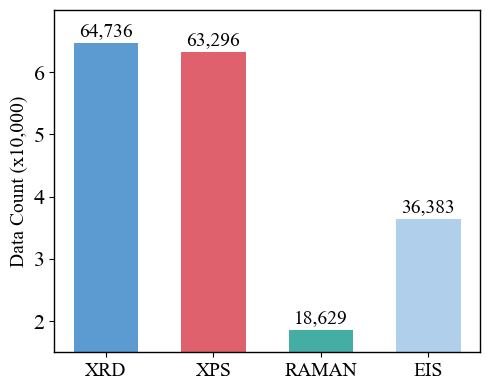

In [56]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

print("开始执行脚本 (数据量统计柱状图 - 调整Y轴刻度)...")

# --- 1. 数据准备 ---
categories = ['XRD', 'XPS', 'RAMAN', 'EIS']
counts = [64736, 63296, 18629, 36383]
colors = ['#3381C7', '#D73949', '#159A8D', '#9DC3E6']
print("数据准备完毕。")

# --- 2. 绘图设置 ---
print("设置绘图样式...")
try:
    fm.findfont("Times New Roman")
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    print("未找到 'Times New Roman' 字体, 将使用默认衬线字体。")
    plt.rcParams['font.family'] = 'serif'

# 创建图表和坐标轴
fig, ax = plt.subplots(figsize=(5, 4)) 
x = np.arange(len(categories)) 
bar_width = 0.6
print("开始生成柱状图...")

# --- 3. 绘制柱状图 ---
# 绘制柱状图 - 高度
# 柱子的高度仍然使用原始的 counts (例如 64736)
bars = ax.bar(x, 
              counts, 
              width=bar_width, 
              color=colors, 
              alpha=0.8,
              zorder=2)

# 4. 在柱状图上添加数值标签
# 标签上的数字也仍然使用原始的 height (例如 64736)
for bar in bars:
    height = bar.get_height() 
    
    ax.text(bar.get_x() + bar.get_width() / 2,   # X位置 (柱子中心)
            height + 500,                       # Y位置 (在原始高度上偏移)
            f'{height:,}',                      # 文本 (原始值)
            ha='center', 
            va='bottom',                        # 垂直对齐底部
            fontsize=14,
            color='black') 
            
# --- 5. 样式调整 ---
print("应用最终样式...")

# X轴
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=14)
ax.set_xlabel(None) 

# --- Y轴 (核心修改点) ---
# 1. 修改Y轴标签以注明单位
ax.set_ylabel('Data Count (x10,000)', fontsize=14) 
ax.tick_params(axis='y', labelsize=16)

# 2. 定义刻度的 "位置" (按原始数据) 和 "标签" (按显示数据)
tick_positions = [10000, 20000, 30000, 40000, 50000, 60000]
tick_labels = ['1', '2', '3', '4', '5', '6']

# 3. 应用新的刻度
ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels)

# 4. 调整 Y 轴范围以显示所有刻度和柱状图
# 必须从 0 开始，才能正确显示柱状图
# 上限设置为 70000，以容纳 "6" (60000) 和 "64,736" 的标签
ax.set_ylim(15000, 70000) 

# --- 其他样式 ---
# 网格线
ax.yaxis.grid(False) # 遵循你代码中的最后设置 (关闭网格线)
ax.xaxis.grid(False) 

# 边框
for spine in ['top', 'bottom', 'left', 'right']:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(1.0)
    
# 调整布局
plt.tight_layout() 

# 保存图表
output_filename = 'data_count_barchart_scaled_y.png'
plt.savefig(output_filename, dpi=1200, bbox_inches='tight')

print(f"脚本执行完毕。柱状图已保存为 {output_filename}")

开始执行脚本 (数据量统计柱状图 - 调整Y轴刻度)...
数据准备完毕。
设置绘图样式...
开始生成柱状图...
应用最终样式...
脚本执行完毕。柱状图已保存为 GCD_CV_C-Rate_Rates_Counts.png


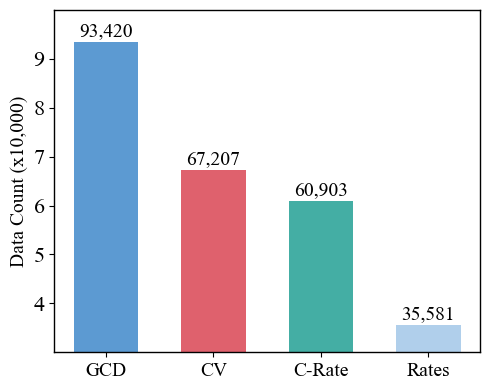

In [59]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

print("开始执行脚本 (数据量统计柱状图 - 调整Y轴刻度)...")

# --- 1. 数据准备 ---
categories = ['GCD', 'CV', 'C-Rate', 'Rates']
counts = [93420, 67207, 60903, 35581]
colors = ['#3381C7', '#D73949', '#159A8D', '#9DC3E6']
print("数据准备完毕。")

# --- 2. 绘图设置 ---
print("设置绘图样式...")
try:
    fm.findfont("Times New Roman")
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    print("未找到 'Times New Roman' 字体, 将使用默认衬线字体。")
    plt.rcParams['font.family'] = 'serif'

# 创建图表和坐标轴
fig, ax = plt.subplots(figsize=(5, 4)) 
x = np.arange(len(categories)) 
bar_width = 0.6
print("开始生成柱状图...")

# --- 3. 绘制柱状图 ---
# 绘制柱状图 - 高度
# 柱子的高度仍然使用原始的 counts (例如 64736)
bars = ax.bar(x, 
              counts, 
              width=bar_width, 
              color=colors, 
              alpha=0.8,
              zorder=2)

# 4. 在柱状图上添加数值标签
# 标签上的数字也仍然使用原始的 height (例如 64736)
for bar in bars:
    height = bar.get_height() 
    
    ax.text(bar.get_x() + bar.get_width() / 2,   # X位置 (柱子中心)
            height + 500,                       # Y位置 (在原始高度上偏移)
            f'{height:,}',                      # 文本 (原始值)
            ha='center', 
            va='bottom',                        # 垂直对齐底部
            fontsize=14,
            color='black') 
            
# --- 5. 样式调整 ---
print("应用最终样式...")

# X轴
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=14)
ax.set_xlabel(None) 

# --- Y轴 (核心修改点) ---
# 1. 修改Y轴标签以注明单位
ax.set_ylabel('Data Count (x10,000)', fontsize=14) 
ax.tick_params(axis='y', labelsize=16)

# 2. 定义刻度的 "位置" (按原始数据) 和 "标签" (按显示数据)
tick_positions = [40000, 50000, 60000, 70000, 80000, 90000]
tick_labels = ['4', '5', '6', '7', '8', '9']

# 3. 应用新的刻度
ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels)

# 4. 调整 Y 轴范围以显示所有刻度和柱状图
# 必须从 0 开始，才能正确显示柱状图
# 上限设置为 70000，以容纳 "6" (60000) 和 "64,736" 的标签
ax.set_ylim(30000, 100000) 

# --- 其他样式 ---
# 网格线
ax.yaxis.grid(False) # 遵循你代码中的最后设置 (关闭网格线)
ax.xaxis.grid(False) 

# 边框
for spine in ['top', 'bottom', 'left', 'right']:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(1.0)
    
# 调整布局
plt.tight_layout() 

# 保存图表
output_filename = 'GCD_CV_C-Rate_Rates_Counts.png'
plt.savefig(output_filename, dpi=1200, bbox_inches='tight')

print(f"脚本执行完毕。柱状图已保存为 {output_filename}")

开始执行脚本 (Y轴4刻度 & 标签微调版)...
绘图完成，已保存为 correct_vs_failed_chart.png


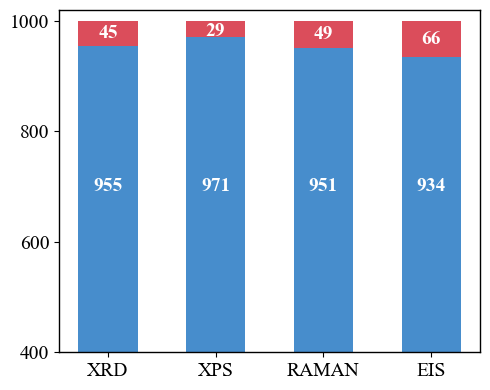

In [62]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

print("开始执行脚本 (Y轴4刻度 & 标签微调版)...")

# --- 1. 数据准备 ---
categories = ['XRD', 'XPS', 'RAMAN', 'EIS']
total_imgs = 1000

# 错误的数据 (Failed)
failed_counts = np.array([45, 29, 49, 66])

# 正确的数据 (Correct)
correct_counts = total_imgs - failed_counts

# 颜色定义
color_correct = '#3381C7' # 蓝色
color_failed = '#D73949'  # 红色

# --- 2. 绘图设置 ---
try:
    fm.findfont("Times New Roman", fontext='ttc', rebuild_if_missing=True)
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    plt.rcParams['font.family'] = 'serif'

fig, ax = plt.subplots(figsize=(5, 4))
x = np.arange(len(categories))
bar_width = 0.55

# --- 3. 绘制堆叠柱状图 ---
# 底部：Correct (蓝色)
p1 = ax.bar(x, 
            correct_counts, 
            width=bar_width, 
            color=color_correct, 
            alpha=0.9, 
            zorder=2)

# 顶部：Failed (红色)
p2 = ax.bar(x, 
            failed_counts, 
            width=bar_width, 
            bottom=correct_counts, 
            color=color_failed, 
            alpha=0.9, 
            zorder=2)

# --- 4. 添加数值标签 ---
font_size_val = 16

# 4.1 标记底部 (Correct)
# 统一显示在视觉舒适区 (Y=700)
for bar in p1:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, 
            700, 
            f'{height}', 
            ha='center', va='center', 
            color='white', fontsize=14, fontweight='bold')

# 4.2 标记顶部 (Failed) - 包含对 29 的特殊调整
for rect_blue, rect_red in zip(p1, p2):
    height_red = rect_red.get_height()     # 红色柱子的高度 (例如 29)
    bottom_pos = rect_blue.get_height()    # 红色柱子的底部起始位置
    
    # 默认中心位置
    y_pos = bottom_pos + height_red / 2
    
    # --- 关键修改：特殊调整 29 的位置 ---
    if height_red == 29:
        y_pos = y_pos - 4  # 向下移动 4 个单位，避免贴顶
    # ----------------------------------
    
    ax.text(rect_red.get_x() + rect_red.get_width() / 2, 
            y_pos, 
            f'{height_red}', 
            ha='center', va='center', 
            color='white', fontsize=14, fontweight='bold')

# --- 5. 样式调整 ---
# X轴
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=14)
ax.set_xlabel(None)

# Y轴
# ax.set_ylabel('Image Count', fontsize=14)
ax.tick_params(axis='y', labelsize=14)

# --- 核心修改：锁定刻度和范围 ---
# 1. 强制设定刻度为 400, 600, 800, 1000
ax.set_yticks([400, 600, 800, 1000])

# 2. 设定显示范围 (稍微超过1000一点点，以免1000的线压住柱子)
ax.set_ylim(400, 1020) 

# 去除网格线
ax.yaxis.grid(False)
ax.xaxis.grid(False)

# 边框设置
for spine in ['top', 'bottom', 'left', 'right']:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(1.0)

plt.tight_layout()

# --- 6. 保存 ---
output_filename = 'correct_vs_failed_chart.png'
plt.savefig(output_filename, dpi=1200, bbox_inches='tight')

print(f"绘图完成，已保存为 {output_filename}")
plt.show()

开始执行脚本 (新数据 GCD/CV/C-Rate/Rates)...
绘图完成，已保存为 count_chart_gcd_cv.png


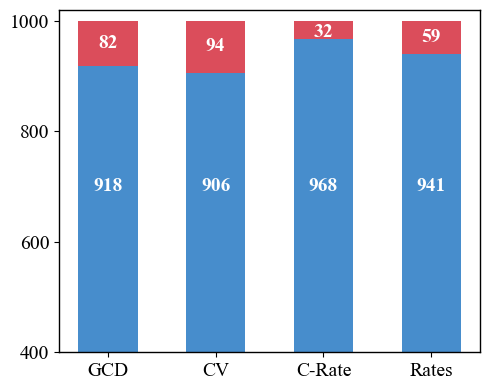

In [63]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

print("开始执行脚本 (新数据 GCD/CV/C-Rate/Rates)...")

# --- 1. 数据准备 ---
categories = ['GCD', 'CV', 'C-Rate', 'Rates']
total_imgs = 1000

# 错误的数据 (Failed)
failed_counts = np.array([82, 94, 32, 59])

# 正确的数据 (Correct)
correct_counts = total_imgs - failed_counts

# 颜色定义
color_correct = '#3381C7' # 蓝色
color_failed = '#D73949'  # 红色

# --- 2. 绘图设置 ---
try:
    fm.findfont("Times New Roman", fontext='ttc', rebuild_if_missing=True)
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    plt.rcParams['font.family'] = 'serif'

fig, ax = plt.subplots(figsize=(5, 4))
x = np.arange(len(categories))
bar_width = 0.55

# --- 3. 绘制堆叠柱状图 ---
# 底部：Correct (蓝色)
p1 = ax.bar(x, 
            correct_counts, 
            width=bar_width, 
            color=color_correct, 
            alpha=0.9, 
            zorder=2)

# 顶部：Failed (红色)
p2 = ax.bar(x, 
            failed_counts, 
            width=bar_width, 
            bottom=correct_counts, 
            color=color_failed, 
            alpha=0.9, 
            zorder=2)

# --- 4. 添加数值标签 ---
font_size_val = 14

# 4.1 标记底部 (Correct)
# 固定在视觉舒适区 (Y=700)
for bar in p1:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, 
            700, 
            f'{height}', 
            ha='center', va='center', 
            color='white', fontsize=14, fontweight='bold')

# 4.2 标记顶部 (Failed)
for rect_blue, rect_red in zip(p1, p2):
    height_red = rect_red.get_height()
    bottom_pos = rect_blue.get_height()
    
    # 默认中心位置
    y_pos = bottom_pos + height_red / 2
    
    # --- 特殊调整 ---
    # 针对较小的数值 (这里是 32)，向下微调以避免贴顶
    if height_red == 32:
        y_pos = y_pos - 4
    
    ax.text(rect_red.get_x() + rect_red.get_width() / 2, 
            y_pos, 
            f'{height_red}', 
            ha='center', va='center', 
            color='white', fontsize=14, fontweight='bold')

# --- 5. 样式调整 ---
# X轴
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=14)
ax.set_xlabel(None)

# Y轴
# ax.set_ylabel('Image Count', fontsize=16)
ax.tick_params(axis='y', labelsize=14)

# 强制设定刻度
ax.set_yticks([400, 600, 800, 1000])

# 设定显示范围
ax.set_ylim(400, 1020) 

# 去除网格线
ax.yaxis.grid(False)
ax.xaxis.grid(False)

# 边框设置
for spine in ['top', 'bottom', 'left', 'right']:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(1.0)

plt.tight_layout()

# --- 6. 保存 ---
output_filename = 'count_chart_gcd_cv.png'
plt.savefig(output_filename, dpi=1200, bbox_inches='tight')

print(f"绘图完成，已保存为 {output_filename}")
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.6789699626126968..1.2342803116996262].
C:\Users\Yin Liang\AppData\Local\Temp\ipykernel_91948\2645562904.py:135: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


图表已保存为: visual_data_mapping_times.png


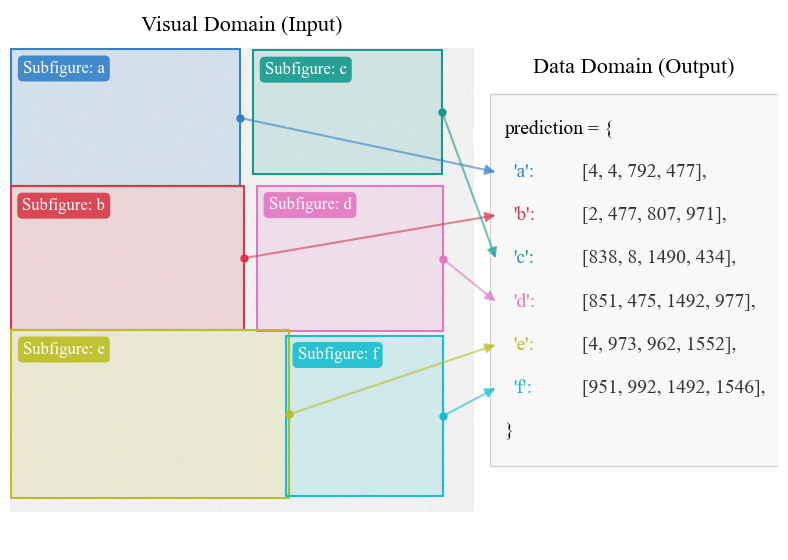

In [14]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import ConnectionPatch
import matplotlib.font_manager as fm
import numpy as np

# --- 0. 全局样式设置 ---
try:
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    print("Warning: Times New Roman not found, using serif.")
    plt.rcParams['font.family'] = 'serif'

FS_TITLE = 16
FS_TEXT = 14
FS_TAG = 12

# --- 1. 模拟数据 ---
img_width, img_height = 1600, 1600
dummy_img = np.ones((img_height, img_width, 3)) * 0.95 
dummy_img += np.random.normal(0, 0.05, (img_height, img_width, 3))

boxes_data = {
    'a': [4, 4, 792, 477],
    'b': [2, 477, 807, 971],
    'c': [838, 8, 1490, 434],
    'd': [851, 475, 1492, 977],
    'e': [4, 973, 962, 1552],
    'f': [951, 992, 1492, 1546]
}

colors = ['#3381C7', '#D73949', '#159A8D', '#E377C2', '#BCBD22', '#17BECF']

# --- 2. 绘图设置 ---
fig = plt.figure(figsize=(8, 6))

# 左侧 (Visual): 保持大尺寸，占据主导
# [left, bottom, width, height]
ax_img = fig.add_axes([0.02, 0.05, 0.58, 0.9]) 

# 右侧 (Data): 
# 这一步很关键：我们保持 Axis 也是全高 (0.9)，方便计算相对位置
# 但我们会在内部只画一个小小的背景框
ax_text = fig.add_axes([0.62, 0.05, 0.36, 0.9]) 
ax_text.axis('off') # 隐藏坐标轴
ax_text.set_xlim(0, 1)
ax_text.set_ylim(0, 1)

# --- 3. 左侧：Visual Domain 绘制 (不变) ---
ax_img.imshow(dummy_img)
ax_img.set_title("Visual Domain (Input)", fontsize=FS_TITLE, pad=12)
ax_img.axis('off')

box_patches = {} 
for i, (key, coords) in enumerate(boxes_data.items()):
    x1, y1, x2, y2 = coords
    w, h = x2 - x1, y2 - y1
    color = colors[i % len(colors)]
    
    rect = patches.Rectangle((x1, y1), w, h, linewidth=0, facecolor=color, alpha=0.15)
    ax_img.add_patch(rect)
    
    rect_border = patches.Rectangle((x1, y1), w, h, linewidth=1.5, edgecolor=color, facecolor='none')
    ax_img.add_patch(rect_border)
    
    ax_img.text(x1 + 40, y1 + 80, f"Subfigure: {key}", color='white', fontsize=FS_TAG,
                bbox=dict(facecolor=color, edgecolor='none', alpha=0.9, boxstyle='round,pad=0.3'))
    
    box_patches[key] = (x2, y1 + h/2, color)

# --- 4. 右侧：Data Domain (紧凑卡片模式) ---

# 4.1 计算所需高度
# 估算：行数 * 行距 + 上下边距
num_lines = len(boxes_data) + 2
line_spacing = 0.08  # 这里的单位是 Axis 的相对高度
padding = 0.05
card_height = (num_lines * line_spacing) + padding
card_bottom = 0.5 - (card_height / 2) # 垂直居中计算
card_top = card_bottom + card_height

# 4.2 绘制紧凑的背景卡片
# 不再填充整个 (0,0,1,1)，而是只填充中间一部分
rect_bg = patches.Rectangle((0, card_bottom), 1, card_height, 
                            facecolor='#f8f8f8', edgecolor='#d0d0d0', linewidth=1, 
                            transform=ax_text.transAxes, zorder=0)
ax_text.add_patch(rect_bg)

# 4.3 放置标题 (紧贴卡片上方)
# 注意：不用 set_title，因为我们要它贴着小卡片，而不是贴着顶端
ax_text.text(0.5, card_top + 0.03, "Data Domain (Output)", 
             fontsize=FS_TITLE, ha='center', va='bottom', color='black')

# 4.4 绘制文字内容
# 这里的 start_y 设为卡片内部
text_start_y = card_top - (padding/2) - line_spacing/2

text_positions = {} 

# 顶部括号
ax_text.text(0.05, text_start_y, "prediction = {", fontsize=FS_TEXT, color='black', va='center')

# 数据行
for i, (key, coords) in enumerate(boxes_data.items()):
    y_pos = text_start_y - (i + 1) * line_spacing
    color = colors[i % len(colors)]
    coord_str = f"[{coords[0]}, {coords[1]}, {coords[2]}, {coords[3]}]"
    
    # Key
    ax_text.text(0.08, y_pos, f"'{key}':", fontsize=FS_TEXT, color=color, va='center')
    
    # Value (x位置设为0.32，拉开一点距离防止重叠)
    ax_text.text(0.32, y_pos, f"{coord_str},", fontsize=FS_TEXT, color='#333333', va='center')
    
    # 记录连线点
    text_positions[key] = (0.02, y_pos)

# 底部括号
ax_text.text(0.05, text_start_y - (len(boxes_data) + 1) * line_spacing, "}", fontsize=FS_TEXT, color='black', va='center')

# --- 5. 绘制连接线 ---
for key, (img_x, img_y, color) in box_patches.items():
    text_x, text_y = text_positions[key]
    
    con = ConnectionPatch(xyA=(img_x, img_y), xyB=(text_x, text_y), 
                          coordsA="data", coordsB="data", 
                          axesA=ax_img, axesB=ax_text,
                          color=color, alpha=0.6, linewidth=1.5,
                          arrowstyle="-|>", mutation_scale=15, 
                          connectionstyle="arc3,rad=0.0")
    fig.add_artist(con)
    
    ax_img.plot(img_x, img_y, 'o', color=color, markersize=5)
    
plt.tight_layout()
output_filename = 'visual_data_mapping_times.png'
plt.savefig(output_filename, dpi=1200, bbox_inches='tight')
print(f"图表已保存为: {output_filename}")
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.6790372878147191..1.2114575448952505].


流程图已保存为: visual_pipeline_tight.png


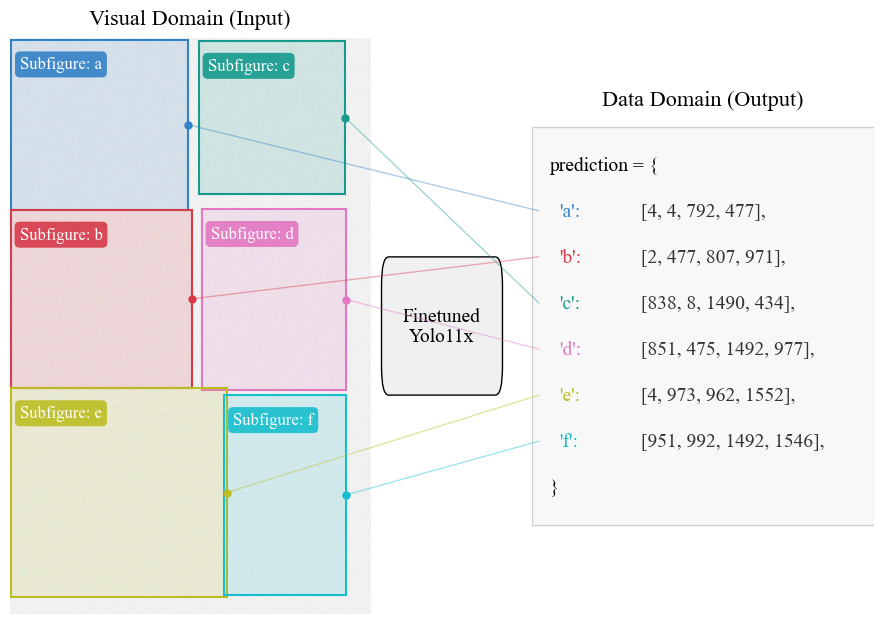

In [36]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import ConnectionPatch, FancyBboxPatch
import matplotlib.font_manager as fm
import numpy as np

# --- 0. 全局样式设置 ---
try:
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    print("Warning: Times New Roman not found, using serif.")
    plt.rcParams['font.family'] = 'serif'

FS_TITLE = 16
FS_TEXT = 14
FS_TAG = 12
FS_MODULE = 14 

# --- 1. 模拟数据 ---
img_width, img_height = 1600, 1600
dummy_img = np.ones((img_height, img_width, 3)) * 0.95 
dummy_img += np.random.normal(0, 0.05, (img_height, img_width, 3))

boxes_data = {
    'a': [4, 4, 792, 477],
    'b': [2, 477, 807, 971],
    'c': [838, 8, 1490, 434],
    'd': [851, 475, 1492, 977],
    'e': [4, 973, 962, 1552],
    'f': [951, 992, 1492, 1546]
}

colors = ['#3381C7', '#D73949', '#159A8D', '#E377C2', '#BCBD22', '#17BECF']

# --- 2. 绘图设置 ---
fig = plt.figure(figsize=(9, 6))

# 修改点1：大幅增加高度占比，减少上下边距
# 以前是 [..., 0.05, ..., 0.90] (上下各留5%)
# 现在是 [..., 0.02, ..., 0.96] (上下仅留2%，非常紧凑)
ax_img = fig.add_axes([0.02, 0.02, 0.40, 0.96]) 
ax_mid = fig.add_axes([0.42, 0.02, 0.16, 0.96]) 
ax_text = fig.add_axes([0.60, 0.02, 0.38, 0.96]) 

for ax in [ax_mid, ax_text]:
    ax.axis('off')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

# --- 3. 左侧：Visual Domain ---
# 修改点2：添加 aspect='auto'
# 这会强制图片拉伸以填满整个 ax_img 区域，防止因为比例不完美而产生内部白边
ax_img.imshow(dummy_img, aspect='auto')

# 标题稍微往下压一点，防止被裁切
ax_img.set_title("Visual Domain (Input)", fontsize=FS_TITLE, pad=10)
ax_img.axis('off')

box_patches = {} 
for i, (key, coords) in enumerate(boxes_data.items()):
    x1, y1, x2, y2 = coords
    w, h = x2 - x1, y2 - y1
    color = colors[i % len(colors)]
    
    rect = patches.Rectangle((x1, y1), w, h, linewidth=0, facecolor=color, alpha=0.15)
    ax_img.add_patch(rect)
    rect_border = patches.Rectangle((x1, y1), w, h, linewidth=1.5, edgecolor=color, facecolor='none')
    ax_img.add_patch(rect_border)
    ax_img.text(x1 + 40, y1 + 80, f"Subfigure: {key}", color='white', fontsize=FS_TAG,
                bbox=dict(facecolor=color, edgecolor='none', alpha=0.9, boxstyle='round,pad=0.3'))
    
    box_patches[key] = (x2, y1 + h/2, color)

# --- 4. 中间：Finetuning YOLO11 模块 ---
# 绘制方框
box_h = 0.2
box_w = 0.8 
box_y = 0.5 - box_h/2
box_x = 0.5 - box_w/2

fancy_box = FancyBboxPatch((box_x, box_y), box_w, box_h,
                           boxstyle="round,pad=0.02,rounding_size=0.05",
                           fc='#f0f0f0', ec='black', lw=1,
                           transform=ax_mid.transAxes, zorder=10)
ax_mid.add_patch(fancy_box)

ax_mid.text(0.5, 0.5, "Finetuned\nYolo11x", 
            transform=ax_mid.transAxes, ha='center', va='center', 
            fontsize=FS_MODULE, color='black', zorder=11)

# --- 5. 右侧：Data Domain ---
num_lines = len(boxes_data) + 2
line_spacing = 0.08 
padding = 0.05
card_height = (num_lines * line_spacing) + padding
card_bottom = 0.5 - (card_height / 2)
card_top = card_bottom + card_height

rect_bg = patches.Rectangle((0, card_bottom), 1, card_height, 
                            facecolor='#f8f8f8', edgecolor='#d0d0d0', linewidth=1, 
                            transform=ax_text.transAxes, zorder=0)
ax_text.add_patch(rect_bg)

ax_text.text(0.5, card_top + 0.03, "Data Domain (Output)", 
             fontsize=FS_TITLE, ha='center', va='bottom', color='black')

text_start_y = card_top - (padding/2) - line_spacing/2
text_positions = {} 

ax_text.text(0.05, text_start_y, "prediction = {", fontsize=FS_TEXT, color='black', va='center')

for i, (key, coords) in enumerate(boxes_data.items()):
    y_pos = text_start_y - (i + 1) * line_spacing
    color = colors[i % len(colors)]
    coord_str = f"[{coords[0]}, {coords[1]}, {coords[2]}, {coords[3]}]"
    
    ax_text.text(0.08, y_pos, f"'{key}':", fontsize=FS_TEXT, color=color, va='center')
    ax_text.text(0.32, y_pos, f"{coord_str},", fontsize=FS_TEXT, color='#333333', va='center')
    text_positions[key] = (0.02, y_pos)

ax_text.text(0.05, text_start_y - (len(boxes_data) + 1) * line_spacing, "}", fontsize=FS_TEXT, color='black', va='center')

# --- 6. 绘制连接线 ---
for key, (img_x, img_y, color) in box_patches.items():
    text_x, text_y = text_positions[key]
    
    con = ConnectionPatch(xyA=(img_x, img_y), xyB=(text_x, text_y), 
                          coordsA="data", coordsB="data", 
                          axesA=ax_img, axesB=ax_text,
                          color=color, alpha=0.4, linewidth=1.0,
                          arrowstyle="-", 
                          connectionstyle="arc3,rad=0.0")
    fig.add_artist(con)
    ax_img.plot(img_x, img_y, 'o', color=color, markersize=5)

# 修改点3：重要！删除 plt.tight_layout()
# 它会破坏 add_axes 的布局，导致意外的边距
# plt.tight_layout() 

output_filename = 'visual_pipeline_tight.png'

# 修改点4：优化 savefig 参数
# pad_inches=0.02 进一步减少周围的白边
plt.savefig(output_filename, dpi=1200, bbox_inches='tight', pad_inches=0.02)
print(f"流程图已保存为: {output_filename}")
plt.show()

C:\Users\Yin Liang\AppData\Local\Temp\ipykernel_39532\874182752.py:21: MatplotlibDeprecationWarning: The tostring_rgb function was deprecated in Matplotlib 3.8 and will be removed in 3.10. Use buffer_rgba instead.
  data = np.frombuffer(fig_dummy.canvas.tostring_rgb(), dtype=np.uint8)


示意图已保存为 fig4a_schematic_simple.png


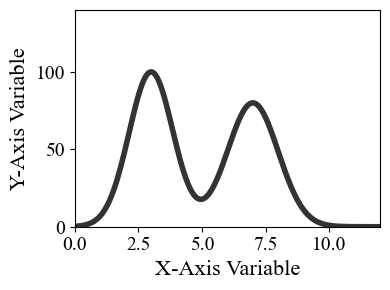

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as patches
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

# --- 1. 全局样式 ---
try:
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    plt.rcParams['font.family'] = 'serif'

# --- 2. 准备“干扰图片” ---
def create_dummy_structure_image():
    fig_dummy, ax_dummy = plt.subplots(figsize=(2, 2), dpi=100)
    x = np.random.rand(15)
    y = np.random.rand(15)
    ax_dummy.scatter(x, y, s=300, c='#BCBD22', edgecolors='black', alpha=0.8)
    ax_dummy.plot(x, y, c='gray', lw=2, alpha=0.5)
    ax_dummy.axis('off')
    fig_dummy.canvas.draw()
    data = np.frombuffer(fig_dummy.canvas.tostring_rgb(), dtype=np.uint8)
    data = data.reshape(fig_dummy.canvas.get_width_height()[::-1] + (3,))
    plt.close(fig_dummy)
    return data

inset_image = create_dummy_structure_image()

# --- 3. 主图绘制 ---
fig, ax = plt.subplots(figsize=(4, 3))

# # 3.1 绘制基础曲线
x = np.linspace(0, 12, 300)
y = 100 * np.exp(-(x - 3)**2 / 1.5) + 80 * np.exp(-(x - 7)**2 / 2.0)
ax.plot(x, y, color='#3381C7', linewidth=4, alpha=0.8, label='Target Spectrum')

# 3.2 制造干扰 1：嵌入图片
# imagebox = OffsetImage(inset_image, zoom=0.8) 
# ab = AnnotationBbox(imagebox, (4.5, 60), frameon=True, 
#                     bboxprops=dict(edgecolor='#BCBD22', linewidth=1, linestyle='--'))
# ax.add_artist(ab)

# ax.annotate('Interference 1:\nEmbedded Image\n(Structure/SEM)', 
#             xy=(4.5, 90), xytext=(2.5, 120),
#             arrowprops=dict(arrowstyle='->', lw=1.5, color='black'),
#             fontsize=14, fontweight='bold', color='#8c8d19')

# 3.3 制造干扰 2：图例遮挡 (Legend Occlusion) --- 修改部分 ---
legend = ax.legend(loc='center', bbox_to_anchor=(0.35, 0.9), 
                   fontsize=14, frameon=False, shadow=False, borderpad=1)
# legend.get_frame().set_facecolor('#f0f0f0')
# legend.get_frame().set_edgecolor('#D73949')
# legend.get_frame().set_linewidth(2)

# 修改说明：
# 1. xy=(7.5, 98): 将箭头尖端向上提，指在图例框的“上边缘” (之前是70，太低了)
# 2. xytext=(8.0, 125): 将文字也相应向上提，避免和曲线重叠
# ax.annotate('Interference 2:\nLegend Occlusion', 
#             xy=(7.0, 120), xytext=(7.5, 125),
#             arrowprops=dict(arrowstyle='->', lw=1.5, color='black'),
#             fontsize=14, fontweight='bold', color='#D73949')

# --- 4. 装饰 ---
ax.set_xlabel("X-Axis Variable", fontsize=16)
ax.set_ylabel("Y-Axis Variable", fontsize=16)
ax.set_xlim(0, 12)
ax.set_ylim(0, 140)

ax.tick_params(axis='both', which='major', labelsize=14)

plt.tight_layout()
output_filename = 'fig3c_schematic_simple.png'
plt.savefig(output_filename, dpi=1200, bbox_inches='tight')
print(f"示意图已保存为 {output_filename}")
plt.show()

In [ ]:
"""
yolo11——axis检测
Class     Images  Instances      Box(P        R      mAP50      mAP50-95): 
all        108        108      0.973      0.998      0.994      0.991

all        108        108      0.981          1      0.994      0.993

all        108        108      0.971      0.998      0.996      0.993

all        108        108      0.980      0.999      0.994      0.995

all        108        108      0.968          1      0.994      0.992


yolo11——legend和clutter检测

Class     Images  Instances      Box(P      R          mAP50      mAP50-95):
all        699    594            0.896      0.842      0.888      0.754
legend     448    486            0.968      0.949      0.980      0.834
clutter    82     108            0.824      0.736      0.796      0.675

Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 
all        699        594      0.846      0.805      0.833      0.698
legend        448        486      0.969      0.952      0.973      0.834
clutter         82        108      0.723      0.657      0.694      0.563

Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 
all        699        594      0.847       0.83      0.854      0.703
legend        448        486      0.949      0.956      0.971      0.833
clutter         82        108      0.746      0.704      0.737      0.574

Class     Images  Instances      Box(P          R      mAP50  mAP50-95):
all        699        594      0.833      0.816      0.829      0.685
legend        448        486       0.95      0.955      0.973      0.837
clutter         82        108      0.716      0.677      0.684      0.534

Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 
all        699        594      0.851      0.826      0.842      0.703
legend        448        486      0.942      0.967      0.971      0.827
clutter         82        108       0.76      0.685      0.713      0.578

"""

图表已保存为 fig_3_barchart_scatter.png


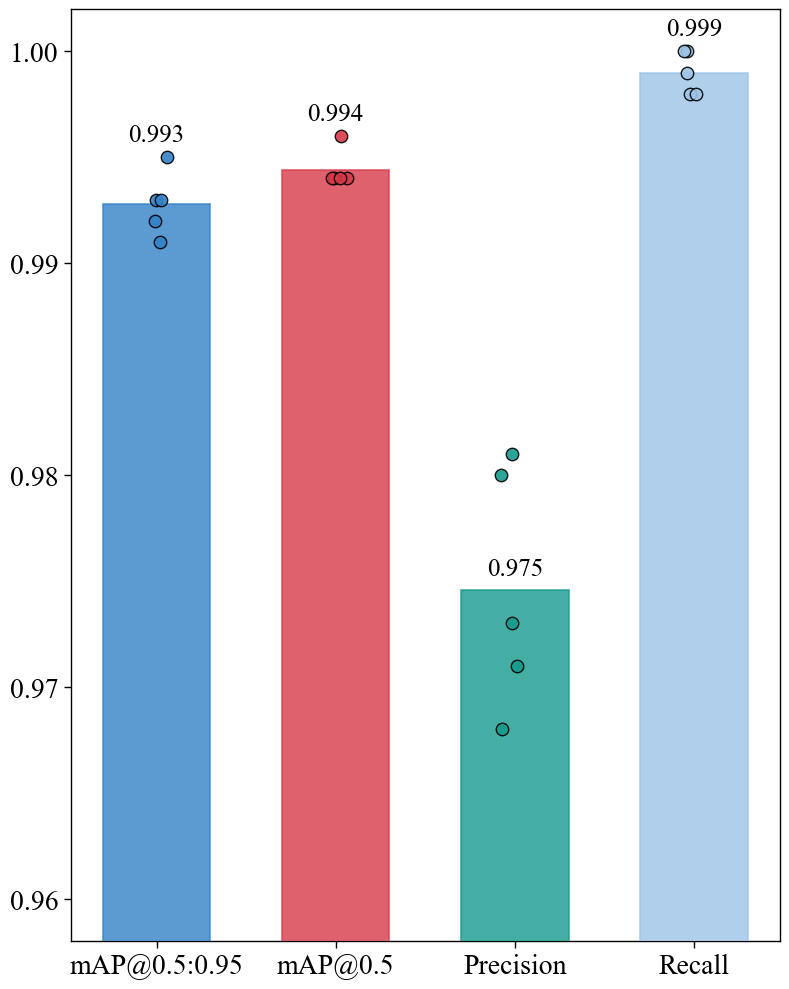

In [107]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. 全局样式设置 ---
try:
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    print("Warning: Times New Roman not found, using serif.")
    plt.rcParams['font.family'] = 'serif'

# 字号设置
FS_LARGE = 16  # 标题、轴标签
FS_SMALL = 14  # 刻度

# 配色
colors = ['#3381C7', '#D73949', '#159A8D', '#9DC3E6']
precision = [0.973, 0.981, 0.971, 0.980, 0.968]
recall    = [0.998, 1.000, 0.998, 0.999, 1.000]
map50     = [0.994, 0.994, 0.996, 0.994, 0.994]
map95     = [0.991, 0.993, 0.993, 0.995, 0.992]

# --- 2. 数据准备 (核心修改：重排顺序) ---
# 目标顺序: ['mAP@0.5:0.95', 'mAP@0.5', 'Precision', 'Recall']

# 1. 重排数据
data = [map95, map50, precision, recall]

# 2. 设置新标签
labels = ['mAP@0.5:0.95', 'mAP@0.5', 'Precision', 'Recall']
# # --- 2. 数据准备 ---
# precision = [0.973, 0.981, 0.971, 0.980, 0.968]
# recall    = [0.998, 1.000, 0.998, 0.999, 1.000]
# map50     = [0.994, 0.994, 0.996, 0.994, 0.994]
# map95     = [0.991, 0.993, 0.993, 0.995, 0.992]

# data = [precision, recall, map50, map95]
# labels = ['Precision', 'Recall', 'mAP 50', 'mAP 50-95']

# 计算平均值用于绘制柱状图
means = [np.mean(d) for d in data]
x_pos = [1, 2, 3, 4]

# --- 3. 绘图 ---
fig, ax = plt.subplots(figsize=(8, 10))

# 3.1 绘制柱状图 (Bar Chart)
# width=0.5 控制柱子宽度
bars = ax.bar(x_pos, means, width=0.6, edgecolor=colors, linewidth=1.2, zorder=5)

# 设置柱子颜色和透明度 (70%透明 = 0.3 alpha)
for bar, color in zip(bars, colors):
    bar.set_facecolor(color)
    bar.set_alpha(0.8)  # 透明度 80%
    bar.set_edgecolor(color) # 边框颜色保持实色

# 3.2 绘制散点图 (Scatter Plot)
np.random.seed(42) 
for i, (d, color) in enumerate(zip(data, colors)):
    # x坐标: i+1 是柱子中心，加上 -0.05 到 0.05 的随机偏移
    x = np.random.normal(i + 1, 0.04, size=len(d))
    
    # 绘制散点 (zorder=10 保证在柱子上面)
    ax.scatter(x, d, color=color, alpha=0.9, s=80, edgecolors='black', linewidth=1.0, zorder=10)

# 3.2.1 在柱状图上方添加数值标签
label_y_positions = [0.9955, 0.9965, 0.975, 1.0005]  # Precision, Recall, mAP50, mAP95
for i, (bar, mean_val, y_pos) in enumerate(zip(bars, means, label_y_positions)):
    ax.text(bar.get_x() + bar.get_width() / 2,  # x位置
            y_pos,  # y位置 (重排后的)
            f'{mean_val:.3f}',  
            ha='center', 
            va='bottom', 
            fontsize=18, 
            color='black',
            zorder=15)

# 3.3 装饰与样式
# Y轴固定5个刻度
ticks = [0.96, 0.97, 0.98, 0.99, 1.00]
ax.set_yticks(ticks)
ax.set_ylim(0.958, 1.002) 

# 标签和字体
# ax.set_ylabel("Metric Score", fontsize=16)
ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels(labels, fontsize=20)

# 刻度字体
ax.tick_params(axis='y', labelsize=20)
# ax.tick_params(axis='x', labelsize=16) # X轴标签字号也设为14，或者根据需要设为16

# 【闭合边框控制】
# 1. 开启所有边框
for spine in ['top', 'bottom', 'left', 'right']:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(1.0)

# 2. 精细控制刻度
# top=False, right=False: 不显示刻度线
# direction='in': 刻度朝内
ax.tick_params(top=False, right=False, left=True, bottom=True, 
               direction='out', width=1.0, length=5)

plt.tight_layout()
output_filename = 'fig_3_barchart_scatter.png'
plt.savefig(output_filename, dpi=1200, bbox_inches='tight')
print(f"图表已保存为 {output_filename}")
plt.show()

图表已保存为 fig3c_axis_detection_single.png


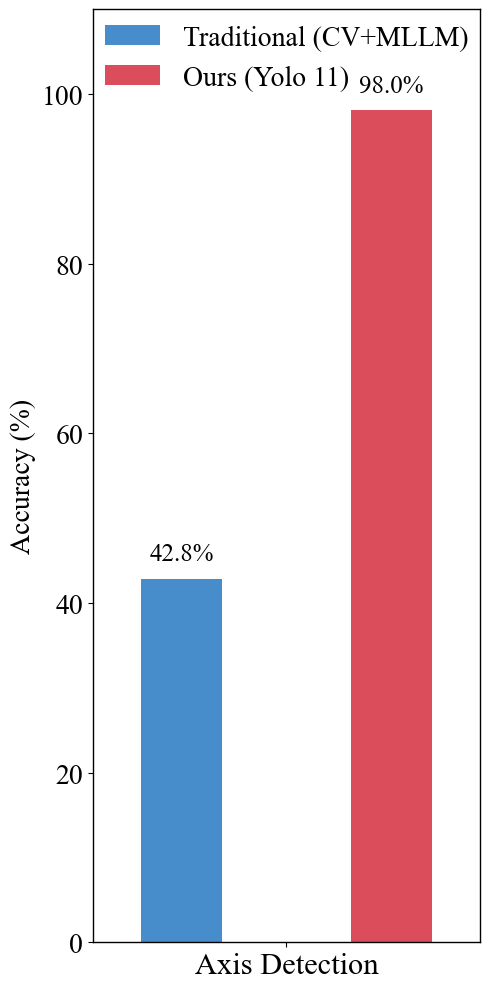

In [106]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. 全局样式设置 ---
try:
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    print("Warning: Times New Roman not found, using serif.")
    plt.rcParams['font.family'] = 'serif'

# 字号设置
FS_TITLE = 16 
FS_LABEL = 16 
FS_TICK = 14  
FS_VAL = 14   

# 配色
c_base = '#3381C7' 
c_ours = '#D73949' 

# --- 2. 数据准备 ---
total_imgs = 2000
acc_base = (830 / 1938) * 100 
acc_ours = (1950 / 1989) * 100 

data_base = [acc_base]
data_ours = [acc_ours]
labels = ['Axis Detection']

# --- 3. 绘图 ---
fig, ax = plt.subplots(figsize=(5, 10))

x = np.arange(len(labels))

# 【核心修改部分：参数化控制】
# 你只需要改这两个数
bar_width = 0.25   # 柱子的宽度 (数值越小越细)
gap = 0.4         # 两个柱子中间的纯空白间隙 (数值越大缝越宽)

# 自动计算偏移量
# 左柱子中心 = 中心点 - 半个间隙 - 半个柱宽
pos_left = x - (gap / 2) - (bar_width / 2)

# 右柱子中心 = 中心点 + 半个间隙 + 半个柱宽
pos_right = x + (gap / 2) + (bar_width / 2)

# 绘制柱子
rects1 = ax.bar(pos_left, data_base, bar_width, label='Traditional (CV+MLLM)', 
                color=c_base, alpha=0.9, edgecolor='black', linewidth=0)

rects2 = ax.bar(pos_right, data_ours, bar_width, label='Ours (Yolo 11)', 
                color=c_ours, alpha=0.9, edgecolor='black', linewidth=0)

# --- 4. 数值标注 ---
def autolabel(rects, is_ours=False):
    for rect in rects:
        height = rect.get_height()
        font_weight = 'normal' if is_ours else 'normal'
        ax.text(rect.get_x() + rect.get_width()/2., height + 1.5,
                f'{height:.1f}%',
                ha='center', va='bottom', fontsize=18, fontweight=font_weight, color='black')

autolabel(rects1, is_ours=False)
autolabel(rects2, is_ours=True)

# --- 5. 样式与装饰 ---
ax.set_ylabel('Accuracy (%)', fontsize=20)

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=22)

# 设置Y轴范围
ax.set_ylim(0, 110) 

# 【关键】：手动限制 X 轴显示范围
# 因为只有一个组，如果不限制，Matplotlib 会自动放大，导致 0.18 的宽度看起来像 0.8 那么粗
# 设置为 -0.6 到 0.6，这样左右留白充足，柱子看起来就是你想要的细度
ax.set_xlim(-0.6, 0.6)

# 设置刻度字体
ax.tick_params(axis='y', labelsize=20)

# 边框设置
for spine in ['top', 'bottom', 'left', 'right']:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(1.0)

# 图例设置
ax.legend(fontsize=20, frameon=False, bbox_to_anchor=(0.5, 1.01), loc='upper center')

plt.tight_layout()
output_filename = 'fig3c_axis_detection_single.png'
plt.savefig(output_filename, dpi=1200, bbox_inches='tight')
print(f"图表已保存为 {output_filename}")
plt.show()

图表已保存为 fig3d_legend_clutter_comparison.png


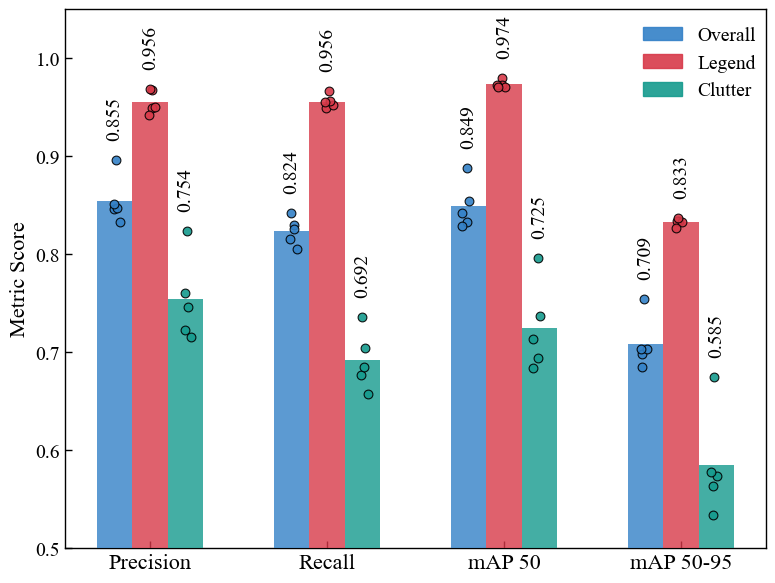

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

# --- 1. 全局样式设置 ---
try:
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    print("Warning: Times New Roman not found, using serif.")
    plt.rcParams['font.family'] = 'serif'

# 字号设置
FS_TITLE = 16 
FS_LABEL = 16 
FS_TICK = 14  
FS_VAL = 14   

# 配色
# Overall: 蓝色
# Legend: 红色
# Clutter: 蓝绿色
colors = ['#3381C7', '#D73949', '#159A8D']
class_names = ['Overall', 'Legend', 'Clutter']

# --- 2. 数据准备 ---
# Overall (All)
all_p     = [0.896, 0.846, 0.847, 0.833, 0.851]
all_r     = [0.842, 0.805, 0.830, 0.816, 0.826]
all_map50 = [0.888, 0.833, 0.854, 0.829, 0.842]
all_map95 = [0.754, 0.698, 0.703, 0.685, 0.703]

# Legend
leg_p     = [0.968, 0.969, 0.949, 0.950, 0.942]
leg_r     = [0.949, 0.952, 0.956, 0.955, 0.967]
leg_map50 = [0.980, 0.973, 0.971, 0.973, 0.971]
leg_map95 = [0.834, 0.834, 0.833, 0.837, 0.827]

# Clutter
clu_p     = [0.824, 0.723, 0.746, 0.716, 0.760]
clu_r     = [0.736, 0.657, 0.704, 0.677, 0.685]
clu_map50 = [0.796, 0.694, 0.737, 0.684, 0.713]
clu_map95 = [0.675, 0.563, 0.574, 0.534, 0.578]

# 数据结构整理
metrics_data = [
    [all_p, leg_p, clu_p],          # Precision Group
    [all_r, leg_r, clu_r],          # Recall Group
    [all_map50, leg_map50, clu_map50], # mAP50 Group
    [all_map95, leg_map95, clu_map95]  # mAP50-95 Group
]
metric_labels = ['Precision', 'Recall', 'mAP 50', 'mAP 50-95']

# --- 3. 绘图设置 ---
fig, ax = plt.subplots(figsize=(8, 6))

# 位置参数
n_metrics = len(metric_labels)
n_classes = len(class_names)
width = 0.2    # 柱子宽度
spacing = 0.00 # 间隙

# X轴基准位置: 1, 2, 3, 4
base_positions = np.arange(1, n_metrics + 1)

# --- 4. 循环绘制分组柱状图 ---
for i in range(n_classes): # 遍历 3 个类别
    # 计算偏移量: Overall偏左, Legend居中, Clutter偏右
    pos_offset = (i - 1) * (width + spacing)
    current_positions = base_positions + pos_offset
    
    # 获取当前类别在4个指标下的数据
    class_raw_data = [metrics_data[m][i] for m in range(n_metrics)]
    
    # 计算平均值 (用于画柱子)
    means = [np.mean(d) for d in class_raw_data]
    
    # 4.1 绘制柱状图 (Bar Chart)
    # alpha=0.3 实现70%透明
    color = colors[i]
    bars = ax.bar(current_positions, means, width, 
           color=color, alpha=0.8, edgecolor=color, linewidth=0, zorder=5)
    
    # 4.2 绘制散点图 (Jitter Scatter)
    np.random.seed(42) # 固定随机数
    for j, d in enumerate(class_raw_data):
        # x坐标增加一点点随机抖动
        x_jitter = np.random.normal(current_positions[j], 0.02, size=len(d))
        
        # 绘制散点
        ax.scatter(x_jitter, d, color=color, alpha=0.9, s=40, 
                   edgecolors='black', linewidth=0.8, zorder=10)
    
    # 4.3 添加均值标签 (在柱体上方，避免与散点重合)
    for j, (bar, mean_val, raw_data) in enumerate(zip(bars, means, class_raw_data)):
        # 找到该组数据的最大值，确保标签位置高于所有散点
        max_val = np.max(raw_data) if len(raw_data) > 0 else mean_val
        # 标签位置 = 最大值 + 偏移量，确保不与散点重合
        label_y = max(max_val, mean_val) + 0.02
        
        ax.text(bar.get_x() + bar.get_width() / 2,  # X位置：柱子中心
                label_y,  # Y位置：在散点上方
                f'{mean_val:.3f}',  # 显示均值，保留3位小数
                ha='center',  # 水平居中
                va='bottom',  # 垂直对齐底部
                fontsize=FS_VAL,  # 字号14
                color='black',
                rotation=90,  # 纵向显示（垂直方向）
                zorder=15)  # 确保标签在最上层

# --- 5. 样式与装饰 ---
ax.set_ylabel("Metric Score", fontsize=FS_LABEL)
ax.set_xticks(base_positions)
ax.set_xticklabels(metric_labels, fontsize=FS_LABEL)

# 设置Y轴范围 (放大差异)
ax.set_ylim(0.5, 1.05)
ax.set_yticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
# 刻度字体
ax.tick_params(axis='y', labelsize=FS_TICK)

# 【核心修改】：去除网格线
ax.yaxis.grid(False)

# 【核心修改】：边框宽度设置为1
for spine in ['top', 'bottom', 'left', 'right']:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(1.0) # 设置为 1

# 刻度线样式 (朝内)
ax.tick_params(top=False, right=False, left=True, bottom=True, 
               direction='in', width=1.0, length=5)

# 自定义图例 (使用矩形块代表柱状图)
legend_patches = [
    mpatches.Patch(color=colors[0], alpha=0.9, label='Overall'),
    mpatches.Patch(color=colors[1], alpha=0.9, label='Legend'),
    mpatches.Patch(color=colors[2], alpha=0.9, label='Clutter')
]

ax.legend(handles=legend_patches, fontsize=14, frameon=False, 
          loc='lower left', bbox_to_anchor=(0.8, 0.8), ncol=1)

plt.tight_layout()
output_filename = 'fig3d_legend_clutter_comparison.png'
plt.savefig(output_filename, dpi=1200, bbox_inches='tight')
print(f"图表已保存为 {output_filename}")
plt.show()

图表已保存为 fig3d_hybrid_bar_box.png


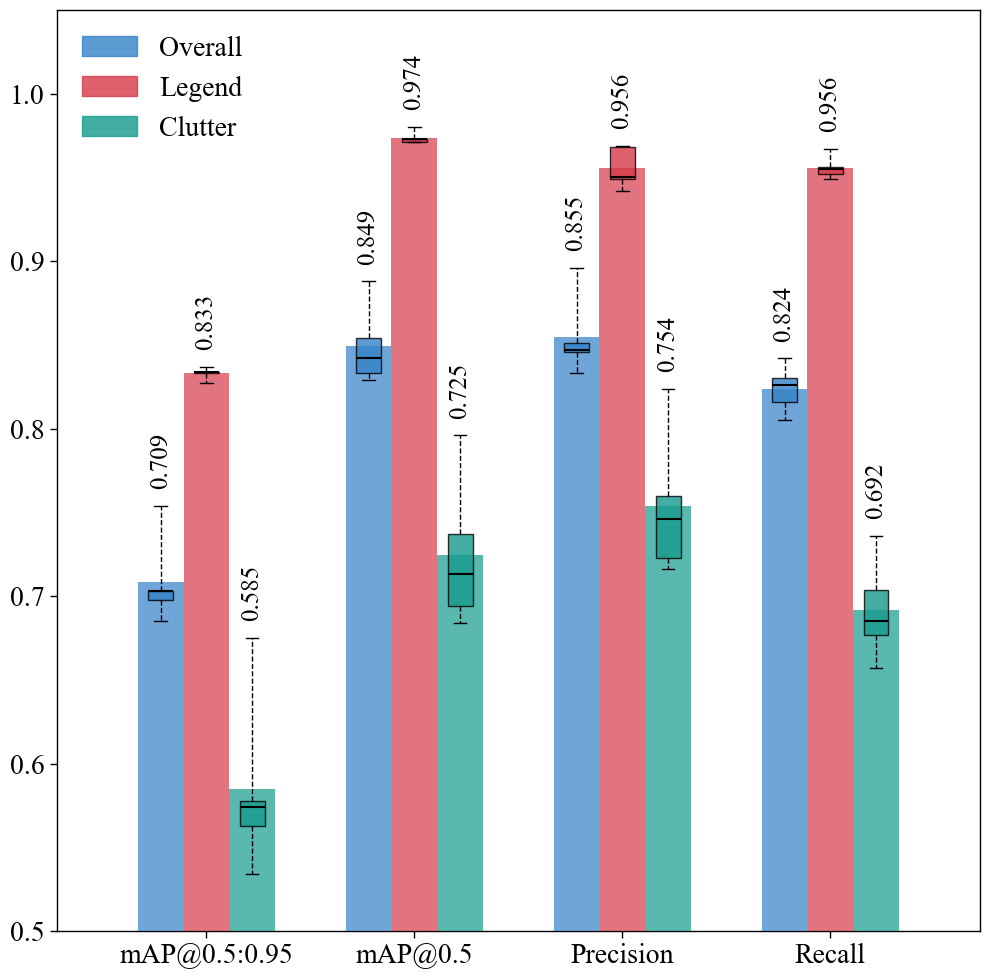

In [102]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

# --- 1. 全局样式设置 ---
try:
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    print("Warning: Times New Roman not found, using serif.")
    plt.rcParams['font.family'] = 'serif'

# 字号设置
FS_TITLE = 16 
FS_LABEL = 16 
FS_TICK = 14  
FS_VAL = 12    # 柱子上数值字号 (稍微调小一点以免太挤)

# 配色
colors = ['#3381C7', '#D73949', '#159A8D']
class_names = ['Overall', 'Legend', 'Clutter']

# --- 2. 数据准备 ---
# Overall (All)
all_p     = [0.896, 0.846, 0.847, 0.833, 0.851]
all_r     = [0.842, 0.805, 0.830, 0.816, 0.826]
all_map50 = [0.888, 0.833, 0.854, 0.829, 0.842]
all_map95 = [0.754, 0.698, 0.703, 0.685, 0.703]

# Legend
leg_p     = [0.968, 0.969, 0.949, 0.950, 0.942]
leg_r     = [0.949, 0.952, 0.956, 0.955, 0.967]
leg_map50 = [0.980, 0.973, 0.971, 0.973, 0.971]
leg_map95 = [0.834, 0.834, 0.833, 0.837, 0.827]

# Clutter
clu_p     = [0.824, 0.723, 0.746, 0.716, 0.760]
clu_r     = [0.736, 0.657, 0.704, 0.677, 0.685]
clu_map50 = [0.796, 0.694, 0.737, 0.684, 0.713]
clu_map95 = [0.675, 0.563, 0.574, 0.534, 0.578]

# 【核心修改】：调整数据顺序
# 顺序: mAP 50-95 -> mAP 50 -> Precision -> Recall
metrics_data = [
    [all_map95, leg_map95, clu_map95], # mAP50-95 Group (Index 0)
    [all_map50, leg_map50, clu_map50], # mAP50 Group    (Index 1)
    [all_p, leg_p, clu_p],             # Precision Group(Index 2)
    [all_r, leg_r, clu_r],             # Recall Group   (Index 3)
]
# 对应的标签
metric_labels = ['mAP@0.5:0.95', 'mAP@0.5', 'Precision', 'Recall']

# --- 3. 绘图设置 ---
fig, ax = plt.subplots(figsize=(10, 10))

n_metrics = len(metric_labels)
n_classes = len(class_names)

# 宽度控制
bar_width = 0.22      
box_width = 0.12      
spacing = 0.00        

base_positions = np.arange(1, n_metrics + 1)

# --- 4. 循环绘制 ---
for i in range(n_classes): 
    # 计算位置
    pos_offset = (i - 1) * (bar_width + spacing)
    current_positions = base_positions + pos_offset
    
    # 获取数据
    class_raw_data = [metrics_data[m][i] for m in range(n_metrics)]
    # 计算均值
    means = [np.mean(d) for d in class_raw_data]
    
    color = colors[i]

    # Step 1: 绘制底层柱状图 (背景)
    bars = ax.bar(current_positions, means, bar_width, 
           color=color, alpha=0.7, edgecolor=color, linewidth=0.0, zorder=5)
    
    # Step 2: 绘制上层箱线图
    bplot = ax.boxplot(class_raw_data, positions=current_positions, widths=box_width,
                        patch_artist=True, 
                        # 【核心修改1】：范围设为0-100，覆盖所有点，不再显示独立离群点
                        whis=(0, 100), 
                        showfliers=False, # 因为whis覆盖了全距，这里设为False即可
                        
                        medianprops=dict(color='black', linewidth=1.5),
                        boxprops=dict(linewidth=1.0, edgecolor='black'), 
                        
                        # 【核心修改2】：须线设置为虚线 '--'
                        whiskerprops=dict(linewidth=1.0, linestyle='--', color='black'),
                        
                        # 【核心修改3】：须盖（那条横线）保持实线
                        capprops=dict(linewidth=1.0, color='black'),
                        zorder=10)
        # 填充箱线图颜色
    for patch in bplot['boxes']:
        patch.set_facecolor(color)   
        patch.set_alpha(0.8)         
        patch.set_edgecolor('black') 

    # Step 3: 添加竖直数值标签
    # 遍历每一组数据，找到最高点，把文字写在上面
    for bar, mean_val, raw_data in zip(bars, means, class_raw_data):
        # 找到该组数据的最大值 (箱线图的上须位置)
        # 如果数据为空，就用均值
        data_max = np.max(raw_data) if len(raw_data) > 0 else mean_val
        
        # 文字的 Y 坐标：最大值 + 0.02 (一点点间隙)
        text_y = data_max + 0.01
        
        ax.text(bar.get_x() + bar.get_width() / 2, # X: 柱子中心
                text_y,                            # Y: 最高点上方
                f'{mean_val:.3f}',                 # 显示内容: 均值
                ha='center', va='bottom',          # 对齐方式
                rotation=90,                       # 【核心修改】垂直旋转
                fontsize=18, 
                color='black',
                zorder=20)

# --- 5. 样式与装饰 ---
# ax.set_ylabel("Metric Score", fontsize=FS_LABEL)
ax.set_xticks(base_positions)
ax.set_xticklabels(metric_labels, fontsize=20)

# 设置Y轴范围 (因为有竖直文字，上限需要调高，否则文字会被切掉)
ax.set_ylim(0.5, 1.05) 
ax.set_yticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])

ax.tick_params(axis='y', labelsize=20)
ax.yaxis.grid(False)

# 边框
for spine in ['top', 'bottom', 'left', 'right']:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(1.0)

ax.tick_params(top=False, right=False, left=True, bottom=True, 
               direction='out', width=1.0, length=5)

# 图例
legend_patches = [
    mpatches.Patch(color=colors[0], alpha=0.8, label='Overall'),
    mpatches.Patch(color=colors[1], alpha=0.8, label='Legend'),
    mpatches.Patch(color=colors[2], alpha=0.8, label='Clutter')
]

ax.legend(handles=legend_patches, fontsize=20, frameon=False, 
          loc='lower left', bbox_to_anchor=(0.0, 0.83), ncol=1)

plt.tight_layout()
output_filename = 'fig3d_hybrid_bar_box.png'
plt.savefig(output_filename, dpi=1200, bbox_inches='tight')
print(f"图表已保存为 {output_filename}")
plt.show()

图表已保存为 fig3d_scale_stacked_bar.png


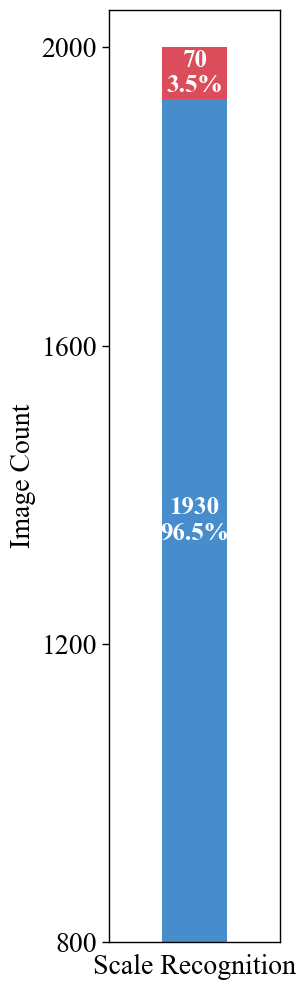

In [108]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. 全局样式设置 ---
try:
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    print("Warning: Times New Roman not found, using serif.")
    plt.rcParams['font.family'] = 'serif'

# 字号设置
FS_LABEL = 16 
FS_TICK = 14  
FS_VAL = 14   

# 配色
c_success = '#3381C7' 
c_fail    = '#D73949' 

# --- 2. 数据准备 ---
total = 2000
success = 1930
failure = 70

pct_success = (success / total) * 100
pct_fail = (failure / total) * 100

# --- 3. 绘图 ---
fig, ax = plt.subplots(figsize=(3, 10))

labels = ['Scale Recognition']

# 【修改点1】将宽度改小，比如 0.15 或 0.12
width = 0.3

# 绘制下层柱子 (Success)
# 【重要修复】这里把原来的 0.2 改成了 width 变量
p1 = ax.bar(labels, success, width, label='Correct', 
            color=c_success, alpha=0.9)

# 绘制上层柱子 (Failure)
p2 = ax.bar(labels, failure, width, bottom=success, label='Failure', 
            color=c_fail, alpha=0.9)

# --- 4. 数值标注 ---
ax.bar_label(p1, labels=[f'{success}\n{pct_success:.1f}%'], label_type='center', 
             fontsize=18, color='white', fontweight='bold')

ax.bar_label(p2, labels=[f'{failure}\n{pct_fail:.1f}%'], label_type='center', 
             fontsize=18, color='white', fontweight='bold')

# --- 5. 样式与装饰 ---
ax.set_ylabel('Image Count', fontsize=20)

# 【修改点2】设置 Y 轴刻度数量为 6 个
# 0 到 2000，每隔 400 一个，刚好 6 个点
ticks = [0, 400, 800, 1200, 1600, 2000]
ax.set_yticks(ticks)
ax.set_ylim(800, 2050) # 稍微高一点留出空间

# 【修改点3】手动限制 X 轴范围，控制视觉上的留白比例
# 因为只有一个柱子在 x=0 的位置，我们将范围设为 -0.4 到 0.4
# 这样 0.15 的宽度看起来就会比较适中，不会占满整个画面
ax.set_xlim(-0.4, 0.4)

# 设置刻度字体
ax.tick_params(axis='y', labelsize=20)
ax.tick_params(axis='x', labelsize=20)

# 边框设置
for spine in ['top', 'bottom', 'left', 'right']:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(1.0)

# 刻度线样式
ax.tick_params(top=False, right=False, left=True, bottom=False, 
               direction='out', width=1.0, length=5)

plt.tight_layout()
output_filename = 'fig3d_scale_stacked_bar.png'
plt.savefig(output_filename, dpi=1200, bbox_inches='tight')
print(f"图表已保存为 {output_filename}")
plt.show()

图片已保存至: fig4a_json_viz_standardized.png


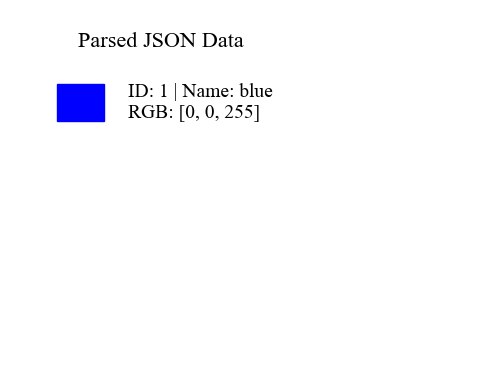

In [7]:
import matplotlib.pyplot as plt
import json
import numpy as np

# --- 绘图标准设置 ---
try:
    # 尝试设置字体为 Times New Roman
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    print("Warning: Times New Roman not found, using serif.")
    plt.rcParams['font.family'] = 'serif'

# 字号设置常量
FS_LABEL = 16  # 用于标题
FS_TICK = 14   # (本例中未用到坐标轴刻度，可备用)
FS_VAL = 14    # 用于具体数值/文本内容

# 你的数据
data = {
    "total_lines_num": 1,
    "lines": [
        {"line_id": 1, "color": "blue", "rgb": [0, 0, 255]}
    ]
}

def create_json_viz(data):
    # 创建画布
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.axis('off') # 关闭坐标轴
    
    # 1. 绘制标题
    # 使用 FS_LABEL 字号，去掉了 fontweight='bold'
    ax.text(0.32, 0.9, f"Parsed JSON Data", 
            ha='center', fontsize=FS_LABEL)
    
    # 起始高度
    y_pos = 0.7
    
    # 2. 循环绘制列表项
    for line in data['lines']:
        # 提取颜色并归一化
        rgb = np.array(line['rgb']) / 255.0
        
        # 绘制色块 (矩形)
        # 色块大小设为 0.1x0.1
        rect = plt.Rectangle((0.1, y_pos), 0.1, 0.1, color=rgb)
        ax.add_patch(rect)
        
        # 绘制文字信息
        # 使用 FS_VAL 字号，移除了 'monospace' 以确保使用全局设置的 Times New Roman
        info_text = f"ID: {line['line_id']} | Name: {line['color']}\nRGB: {line['rgb']}"
        ax.text(0.25, y_pos + 0.05, info_text, 
                va='center', fontsize=FS_VAL)
        
        # 更新下一个条目的位置
        y_pos -= 0.25  #稍微增加间距以适应较大的字号

    plt.tight_layout()
    
    # 保存图片，分辨率设为1200 dpi
    save_path = "fig4a_json_viz_standardized.png"
    plt.savefig(save_path, dpi=1200)
    print(f"图片已保存至: {save_path}")
    
    plt.show()

if __name__ == "__main__":
    create_json_viz(data)

In [ ]:
"""
Our Work:
---------------------------------------------------------------------------
【整体评估】(所有线条合并为一个掩码进行对比)
---------------------------------------------------------------------------
  点覆盖率 (Point Coverage):  85.67%
  平均 IoU:                   0.2060
  平均 Dice:                  0.3237
  平均 Precision:             0.7086
  平均 Recall:                0.2427
  平均 F1 Score:              0.3237
  平均像素距离:               3.79 px

---------------------------------------------------------------------------
【分线评估】(按线条分别匹配后评估)
---------------------------------------------------------------------------
  点覆盖率 (Point Coverage):  76.95%
  平均 IoU:                   0.2831
  平均 Dice:                  0.3962
  平均 Precision:             0.6025
  平均 Recall:                0.3424
  平均 F1 Score:              0.3962
  平均像素距离:               12.55 px


CV+Kmeans: 
---------------------------------------------------------------------------
【整体评估】(所有线条合并为一个掩码进行对比)
---------------------------------------------------------------------------
  点覆盖率 (Point Coverage):  88.95%
  平均 IoU:                   0.1964
  平均 Dice:                  0.3174
  平均 Precision:             0.6909
  平均 Recall:                0.2464
  平均 F1 Score:              0.3174
  平均像素距离:               5.46 px

---------------------------------------------------------------------------
【分线评估】(按线条分别匹配后评估)
---------------------------------------------------------------------------
  点覆盖率 (Point Coverage):  76.39%
  平均 IoU:                   0.2449
  平均 Dice:                  0.3731
  平均 Precision:             0.5571
  平均 Recall:                0.3268
  平均 F1 Score:              0.3731
  平均像素距离:               nan px


ChartOCR
---------------------------------------------------------------------------
【整体评估】(所有线条合并为一个掩码进行对比)
---------------------------------------------------------------------------
  点覆盖率 (Point Coverage):  53.99%
  平均 IoU:                   0.1420
  平均 Dice:                  0.2385
  平均 Precision:             0.5871
  平均 Recall:                0.1649
  平均 F1 Score:              0.2385
  平均像素距离:               21.55 px

---------------------------------------------------------------------------
【分线评估】(按线条分别匹配后评估)
---------------------------------------------------------------------------
  点覆盖率 (Point Coverage):  48.11%
  平均 IoU:                   0.2335
  平均 Dice:                  0.3330
  平均 Precision:             0.4295
  平均 Recall:                0.3030
  平均 F1 Score:              0.3330
  平均像素距离:               35.66 px
===========================================================================


Segment3
---------------------------------------------------------------------------
【整体评估】(所有线条合并为一个掩码进行对比)
---------------------------------------------------------------------------
  点覆盖率 (Point Coverage):  54.35%
  平均 IoU:                   0.1237
  平均 Dice:                  0.2038
  平均 Precision:             0.3506
  平均 Recall:                0.1807
  平均 F1 Score:              0.2038
  平均像素距离:               24.59 px

---------------------------------------------------------------------------
【分线评估】(按线条分别匹配后评估)
---------------------------------------------------------------------------
  点覆盖率 (Point Coverage):  56.91%
  平均 IoU:                   0.3209
  平均 Dice:                  0.4230
  平均 Precision:             0.6649
  平均 Recall:                0.3664
  平均 F1 Score:              0.4230
  平均像素距离:               89.63 px


Unet++
---------------------------------------------------------------------------
【整体评估】(所有线条合并为一个掩码进行对比)
---------------------------------------------------------------------------
  点覆盖率 (Point Coverage):  75.57%
  平均 IoU:                   0.2298
  平均 Dice:                  0.3608
  平均 Precision:             0.3754
  平均 Recall:                0.4730
  平均 F1 Score:              0.3608
  平均像素距离:               5.91 px

---------------------------------------------------------------------------
【分线评估】(使用连通区域分离预测，与手动标注线条匹配后评估)
---------------------------------------------------------------------------
  点覆盖率 (Point Coverage):  59.50%
  平均 IoU:                   0.1210
  平均 Dice:                  0.2091
  平均 Precision:             0.2150
  平均 Recall:                0.4470
  平均 F1 Score:              0.2091
  平均像素距离:               48.31 px
===========================================================================


WebPlotDigitizer: 这个比对是放在最后的，强调的是半自动和全自动的处理方式，六万张数据处理要多久时间评估一下，再加上我们使用的自动处理时间上的对比。
"""

'\nPixel Range Classification:\n\n\nCV+Kmeans: \n\n\nWebPlotDigitizer: \n\n'

In [26]:
import json
with open(r"C:\Users\Yin Liang\中科院博士\论文\多模态识别（图片信息）\NeuroLore-master\multi-modal NER\graph_to_structure_data\ztest_battery_life\synthesis.json", "r", encoding="utf-8") as f:
    data = json.load(f)
count = len(data)
print(count)


47715


图表已保存为 fig4_overall_evaluation2.png


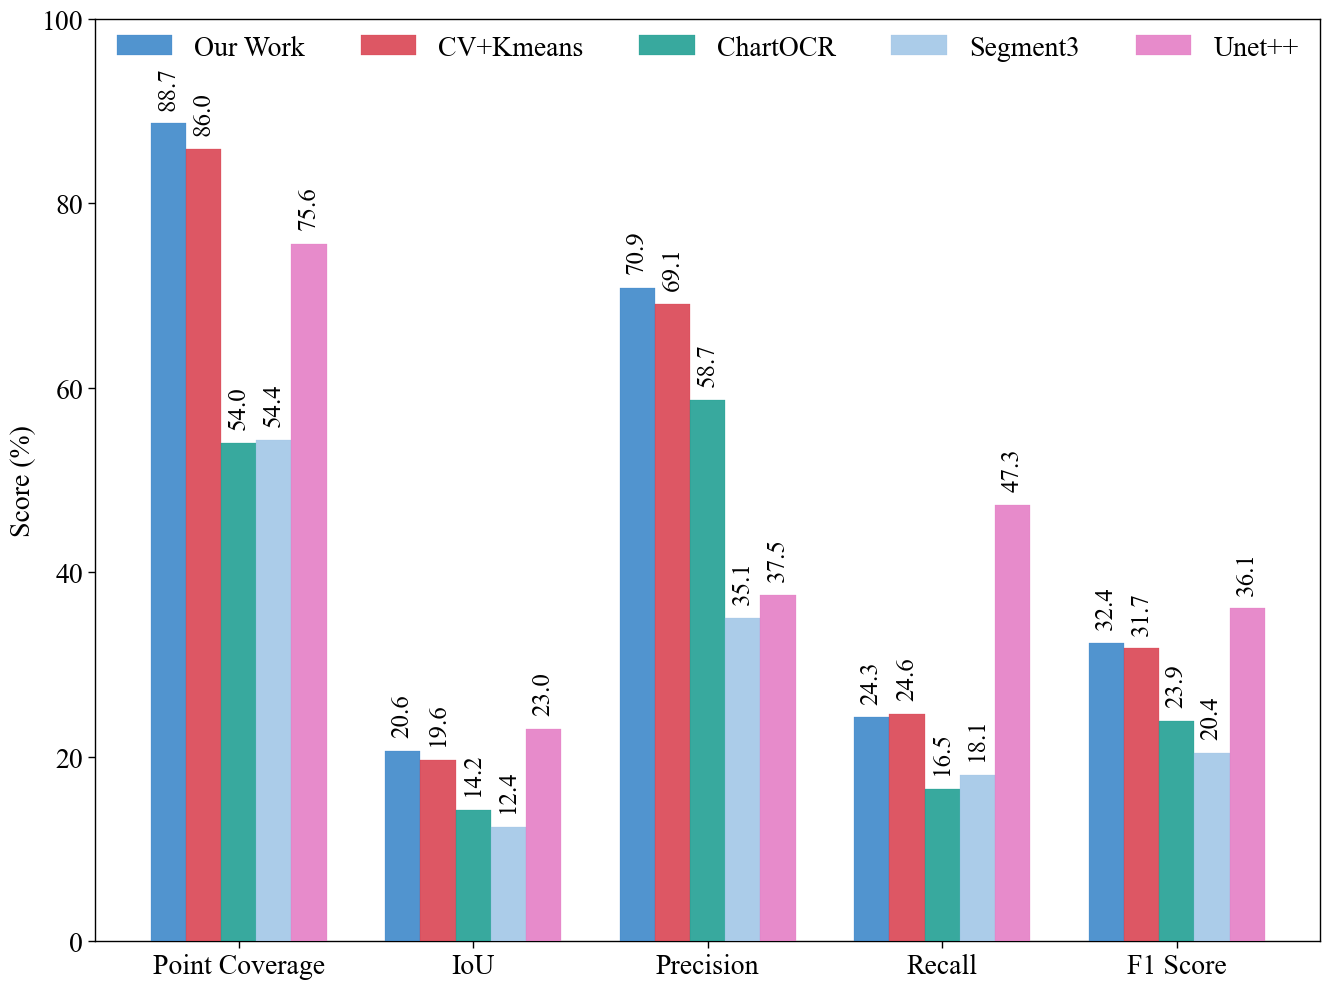

图表已保存为 fig4_perline_evaluation2.png


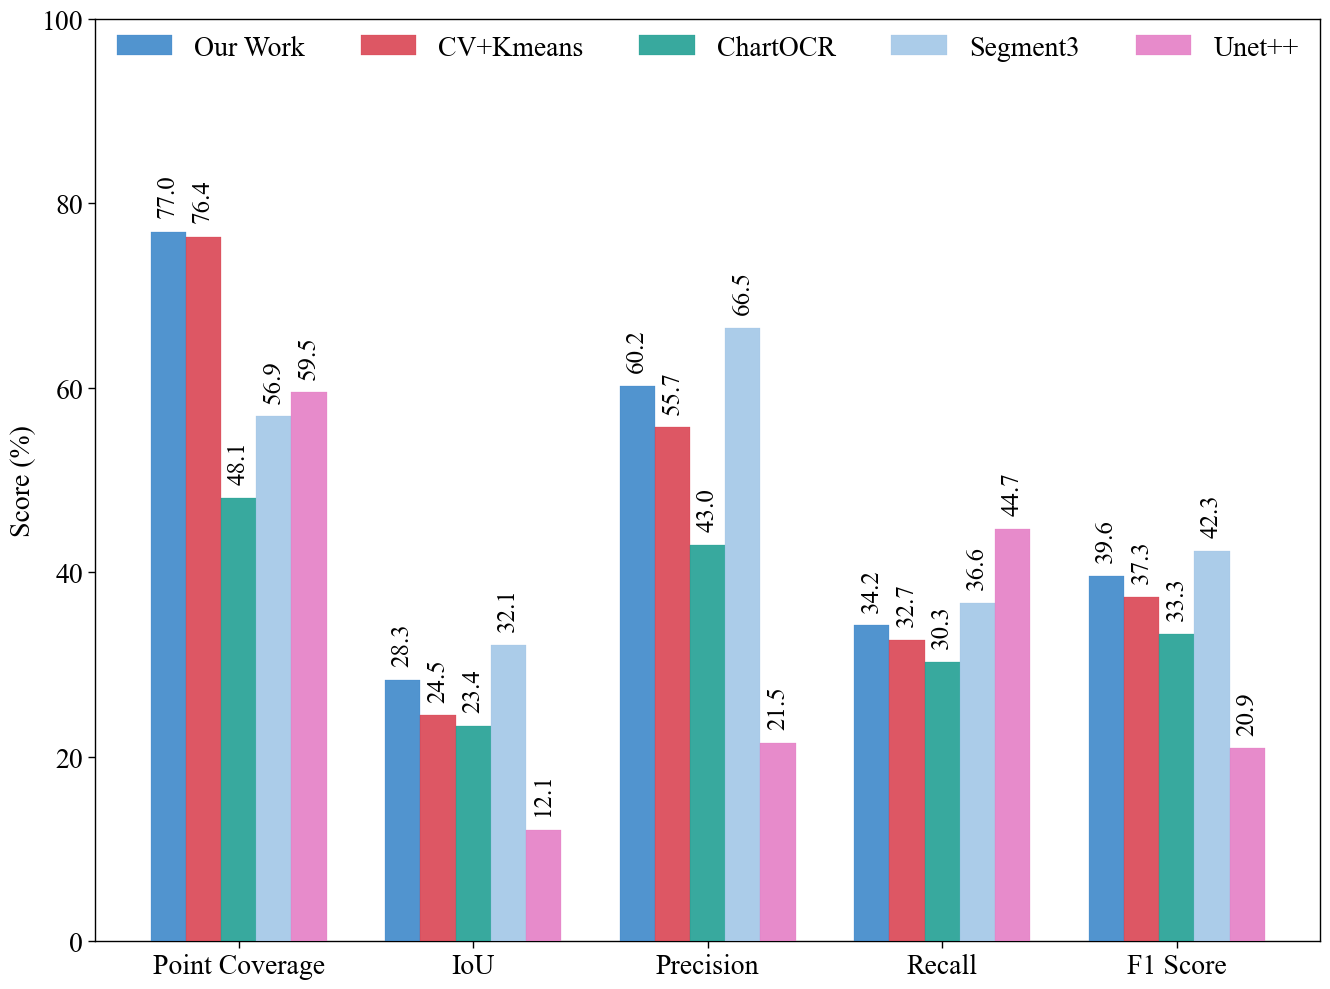

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. 全局样式设置 ---
try:
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    print("Warning: Times New Roman not found, using serif.")
    plt.rcParams['font.family'] = 'serif'

# 字号设置
FS_LABEL = 20 
FS_TICK = 18 
FS_VAL = 18   

# 配色 - Our Work使用红色(#D73949) ['#9DC3E6', '#159A8D', '#3381C7', '#D73949']
# 方法顺序: Our Work, CV+Kmeans, ChartOCR, Segment3, Unet++ 
colors = ['#3381C7', '#D73949', '#159A8D', '#9DC3E6', '#E377C2']
methods = ['Our Work', 'CV+Kmeans', 'ChartOCR', 'Segment3', 'Unet++']

# --- 2. 数据准备 ---
# 整体评估数据 (转换为百分比 0-100)
overall_data = {
    'Point Coverage': [88.67, 85.95, 53.99, 54.35, 75.57],
    'IoU':            [20.60, 19.64, 14.20, 12.37, 22.98],
    'Precision':      [70.86, 69.09, 58.71, 35.06, 37.54],
    'Recall':         [24.27, 24.64, 16.49, 18.07, 47.30],
    'F1 Score':       [32.37, 31.74, 23.85, 20.38, 36.08]
}

# 分线评估数据 (转换为百分比 0-100)
perline_data = {
    'Point Coverage': [76.95, 76.39, 48.11, 56.91, 59.50],
    'IoU':            [28.31, 24.49, 23.35, 32.09, 12.10],
    'Precision':      [60.25, 55.71, 42.95, 66.49, 21.50],
    'Recall':         [34.24, 32.68, 30.30, 36.64, 44.70],
    'F1 Score':       [39.62, 37.31, 33.30, 42.30, 20.91]
}

metrics = list(overall_data.keys())

# --- 3. 绘图函数 ---
def plot_comparison_chart(data, title, output_filename):
    """绘制分组柱状图"""
    fig, ax = plt.subplots(figsize=(14, 10))
    
    n_metrics = len(metrics)
    n_methods = len(methods)
    
    # X轴位置
    x = np.arange(n_metrics)
    
    # 柱状图参数
    total_width = 0.75
    bar_width = total_width / n_methods
    
    # 绘制每个方法的柱状图
    for i, method in enumerate(methods):
        # 获取该方法在各指标上的值
        values = [data[metric][i] for metric in metrics]
        
        # 计算位置偏移
        positions = x + (i - (n_methods - 1) / 2) * bar_width
        
        # 绘制柱状图
        bars = ax.bar(positions, values, bar_width, 
                      color=colors[i], alpha=0.85, 
                      label=method, edgecolor=colors[i], linewidth=0.2,
                      zorder=5)
        
        # 在柱子上方添加数值标签
        for bar, val in zip(bars, values):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2, 
                    height + 1.5,  # 略微偏移
                    f'{val:.1f}',
                    ha='center', va='bottom',
                    fontsize=18, color='black',
                    rotation=90,
                    zorder=10)
    
    # --- 4. 样式设置 ---
    # Y轴
    ax.set_ylabel('Score (%)', fontsize=FS_LABEL)
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 20, 40, 60, 80, 100])
    ax.tick_params(axis='y', labelsize=FS_LABEL)
    
    # X轴
    ax.set_xticks(x)
    ax.set_xticklabels(metrics, fontsize=FS_LABEL)
    
    # 边框
    for spine in ['top', 'bottom', 'left', 'right']:
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_linewidth(1.0)
    
    # 刻度线样式
    ax.tick_params(top=False, right=False, left=True, bottom=True, 
                   direction='out', width=1.0, length=5)
    
    # 图例
    ax.legend(fontsize=FS_LABEL, frameon=False, 
              loc='upper center', bbox_to_anchor=(0.5, 1.01), 
              ncol=n_methods)
    
    plt.tight_layout()
    plt.savefig(output_filename, dpi=1200, bbox_inches='tight')
    print(f"图表已保存为 {output_filename}")
    plt.show()

# --- 5. 绘制两张图 ---
# 整体评估图
plot_comparison_chart(overall_data, 
                      'Overall Evaluation (All Lines Merged as One Mask)', 
                      'fig4_overall_evaluation2.png')

# 分线评估图
plot_comparison_chart(perline_data, 
                      'Per-line Evaluation (Matched by Individual Lines)', 
                      'fig4_perline_evaluation2.png')


In [ ]:
"""
============================================================
2026-01-09 10:54:09,261 - INFO - 统计结果：
2026-01-09 10:54:09,261 - INFO -   - 文章总数: 47714
2026-01-09 10:54:09,261 - INFO -   - 同时有TEM和c_rate的文章数: 19316
2026-01-09 10:54:09,261 - INFO -
2026-01-09 10:54:09,261 - INFO -   在同时有TEM和c_rate的条件下，各表征类型的文章数量：
2026-01-09 10:54:09,261 - INFO -       XRD: 15539
2026-01-09 10:54:09,261 - INFO -       XPS: 10098
2026-01-09 10:54:09,261 - INFO -       RAMAN: 6747
2026-01-09 10:54:09,261 - INFO -       EIS: 10305
2026-01-09 10:54:09,261 - INFO -       IR: 2425
2026-01-09 10:54:09,261 - INFO -       EXAFS: 540
2026-01-09 10:54:09,261 - INFO -       DOS: 564
2026-01-09 10:54:09,261 - INFO - ============================================================
"""

'\n============================================================\n2026-01-09 10:54:09,261 - INFO - 统计结果：\n2026-01-09 10:54:09,261 - INFO -   - 文章总数: 47714\n2026-01-09 10:54:09,261 - INFO -   - 同时有TEM和c_rate的文章数: 19316\n2026-01-09 10:54:09,261 - INFO -\n2026-01-09 10:54:09,261 - INFO -   在同时有TEM和c_rate的条件下，各表征类型的文章数量：\n2026-01-09 10:54:09,261 - INFO -       XRD: 15539\n2026-01-09 10:54:09,261 - INFO -       XPS: 10098\n2026-01-09 10:54:09,261 - INFO -       RAMAN: 6747\n2026-01-09 10:54:09,261 - INFO -       EIS: 10305\n2026-01-09 10:54:09,261 - INFO -       IR: 2425\n2026-01-09 10:54:09,261 - INFO -       EXAFS: 540\n2026-01-09 10:54:09,261 - INFO -       DOS: 564\n2026-01-09 10:54:09,261 - INFO - ============================================================\n'

In [ ]:
"""
plot_embedding_distribution.py
==============================
生成三类可视化图:
  1. TEM embedding PCA 2D 映射
  2. XRD 数据分布 (叠加谱图 + PCA降维)
  3. C-rate 容量保有率曲线 (过滤78%以下, 渐变色)

仅依赖 numpy + matplotlib，不需要 sklearn。
"""
import json
import sys
import io
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

# if sys.platform == "win32":
#     sys.stdout = io.TextIOWrapper(sys.stdout.buffer, encoding='utf-8', errors='replace')
#     sys.stderr = io.TextIOWrapper(sys.stderr.buffer, encoding='utf-8', errors='replace')

# ---------------------------------------------------------------------------
# 风格与全局设置
# ---------------------------------------------------------------------------
try:
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    plt.rcParams['font.family'] = 'serif'

FS_TITLE = 16
FS_LABEL = 14
FS_TICK = 12
colors = ['#3381C7', '#D73949', '#159A8D', '#9DC3E6']

# 统一图片大小
FIG_SIZE = (10, 8)

ROOT = Path(r"C:\Users\Yin Liang\中科院博士\论文\多模态识别（图片信息）\batterylife")
DATA_ROOT = ROOT / "batterylife"
INDEX_PATH = ROOT / "localmodel" / "embeddings_full" / "embedding_index_clean.json"
OUT_DIR = ROOT / "localmodel" / "analysis_plots" / "embedding_viz"
OUT_DIR.mkdir(parents=True, exist_ok=True)

with open(INDEX_PATH, "r", encoding="utf-8") as f:
    all_entries = json.load(f)

print(f"Total entries: {len(all_entries)}")


# ---------------------------------------------------------------------------
# 纯numpy PCA
# ---------------------------------------------------------------------------
def pca_2d(X: np.ndarray) -> np.ndarray:
    """PCA降维到2D，纯numpy实现"""
    X = X - X.mean(axis=0)
    # 标准化
    std = X.std(axis=0)
    std[std == 0] = 1.0
    X = X / std
    # SVD
    U, S, Vt = np.linalg.svd(X, full_matrices=False)
    return U[:, :2] * S[:2]


# ===================================================================
# 1. TEM Embedding PCA
# ===================================================================
def plot_tem():
    print("\n=== TEM Embedding PCA ===")
    embeddings = []
    battery_indices = []

    for entry in all_entries:
        tem_path = entry.get("tem_embedding")
        if not tem_path:
            continue
        full_path = ROOT / tem_path.replace("\\", "/")
        if not full_path.exists():
            continue
        emb = np.load(str(full_path))
        if emb.shape == (1024,):
            embeddings.append(emb)
            battery_indices.append(entry.get("info", {}).get("battery_index", 0))

    print(f"  Loaded {len(embeddings)} TEM embeddings")
    if len(embeddings) < 10:
        print("  Too few, skip.")
        return

    X = np.array(embeddings, dtype=np.float32)
    X2d = pca_2d(X)

    bidx = np.array(battery_indices)
    unique_bidx = sorted(set(bidx))

    # 使用统一大小
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    cmap = plt.cm.tab10
    for i, b in enumerate(unique_bidx):
        mask = bidx == b
        ax.scatter(X2d[mask, 0], X2d[mask, 1],
                   c=[cmap(i % 10)], s=12, alpha=0.5,
                   label=f'battery_{b}', edgecolors='none')

    ax.set_xlabel('PC 1', fontsize=FS_LABEL)
    ax.set_ylabel('PC 2', fontsize=FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
    if len(unique_bidx) <= 15:
        ax.legend(fontsize=8, markerscale=2, loc='best', framealpha=0.7)
    fig.tight_layout()
    out = OUT_DIR / "tem_embedding_pca.png"
    fig.savefig(str(out), dpi=200, bbox_inches='tight')
    plt.close(fig)
    print(f"  Saved: {out}")


# ===================================================================
# 2. XRD Data Distribution
# ===================================================================
def plot_xrd():
    print("\n=== XRD Data Distribution ===")
    xrd_raw = []
    xrd_interp = []
    battery_indices = []

    grid_2theta = np.linspace(5, 70, 256)

    for entry in all_entries:
        xrd_path = entry.get("xrd_data")
        if not xrd_path:
            continue
        full_path = ROOT / xrd_path.replace("\\", "/")
        if not full_path.exists():
            continue
        xrd = np.load(str(full_path))
        if xrd.ndim != 2 or xrd.shape[1] != 2 or len(xrd) < 10:
            continue

        angles, intensities = xrd[:, 0], xrd[:, 1]
        xrd_raw.append((angles, intensities))
        battery_indices.append(entry.get("info", {}).get("battery_index", 0))
        xrd_interp.append(np.interp(grid_2theta, angles, intensities, left=0, right=0))

    print(f"  Loaded {len(xrd_raw)} XRD patterns")
    if len(xrd_raw) < 10:
        print("  Too few, skip.")
        return

    # --- 2a: XRD叠加谱图 ---
    # 使用统一大小
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    n_show = min(500, len(xrd_raw))
    rng = np.random.RandomState(42)
    indices = rng.choice(len(xrd_raw), n_show, replace=False)
    for idx in indices:
        angles, intensities = xrd_raw[idx]
        imin, imax = intensities.min(), intensities.max()
        inorm = (intensities - imin) / (imax - imin) if imax > imin else intensities * 0
        ax.plot(angles, inorm, alpha=0.03, linewidth=0.5, color=colors[0])

    ax.set_xlabel(r'2θ (degree)', fontsize=FS_LABEL)
    ax.set_ylabel('Normalized Intensity', fontsize=FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
    ax.set_xlim(5, 70)
    ax.set_ylim(-0.05, 1.05)
    fig.tight_layout()
    out = OUT_DIR / "xrd_pattern_overlay.png"
    fig.savefig(str(out), dpi=200, bbox_inches='tight')
    plt.close(fig)
    print(f"  Saved: {out}")

    # --- 2b: XRD PCA (先归一化每条谱，再去离群点) ---
    X = np.array(xrd_interp, dtype=np.float32)
    row_max = X.max(axis=1, keepdims=True)
    row_min = X.min(axis=1, keepdims=True)
    denom = row_max - row_min
    denom[denom == 0] = 1.0
    X = (X - row_min) / denom
    X2d = pca_2d(X)
    bidx = np.array(battery_indices)

    mask_inlier = np.ones(len(X2d), dtype=bool)
    for dim in range(2):
        mu, sigma = X2d[:, dim].mean(), X2d[:, dim].std()
        mask_inlier &= np.abs(X2d[:, dim] - mu) < 3 * sigma
    X2d = X2d[mask_inlier]
    bidx = bidx[mask_inlier]
    print(f"  After outlier removal: {len(X2d)} samples")

    unique_bidx = sorted(set(bidx))

    # 使用统一大小
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    cmap = plt.cm.tab10
    for i, b in enumerate(unique_bidx):
        mask = bidx == b
        ax.scatter(X2d[mask, 0], X2d[mask, 1],
                   c=[cmap(i % 10)], s=12, alpha=0.5,
                   label=f'battery_{b}', edgecolors='none')

    ax.set_xlabel('PC 1', fontsize=FS_LABEL)
    ax.set_ylabel('PC 2', fontsize=FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
    if len(unique_bidx) <= 15:
        ax.legend(fontsize=8, markerscale=2, loc='best', framealpha=0.7)
    fig.tight_layout()
    out = OUT_DIR / "xrd_embedding_pca.png"
    fig.savefig(str(out), dpi=200, bbox_inches='tight')
    plt.close(fig)
    print(f"  Saved: {out}")


# ===================================================================
# 3. C-rate 容量保有率曲线 (渐变色, 过滤78%以下)
# # ===================================================================
# def plot_crate_retention():
#     print("\n=== C-rate Capacity Retention Curves ===")

#     cleaned_files = sorted(DATA_ROOT.glob("*/c_rate/*_cleaned.json"))
#     cleaned_files = [f for f in cleaned_files if "nothink" not in f.name]
#     print(f"  Found {len(cleaned_files)} cleaned files")

#     all_curves = []
#     for cf in cleaned_files:
#         try:
#             with open(cf, "r", encoding="utf-8") as fh:
#                 d = json.load(fh)
#             for curve in d.get("curves", []):
#                 cycles = curve.get("cycles", [])
#                 caps = curve.get("capacities", [])
#                 if len(cycles) >= 5 and len(caps) >= 5 and len(cycles) == len(caps):
#                     cap1 = caps[0]
#                     if cap1 > 0:
#                         retention = [c / cap1 * 100.0 for c in caps]
#                         min_retention = min(retention)
#                         all_curves.append({
#                             "cycles": cycles,
#                             "retention": retention,
#                             "min_retention": min_retention,
#                             "max_cycle": max(cycles),
#                             "name": curve.get("name", ""),
#                             "sample_id": d.get("sample_id", ""),
#                         })
#         except Exception:
#             continue

#     print(f"  Total curves parsed: {len(all_curves)}")

#     filtered = [c for c in all_curves if c["min_retention"] >= 78.0]
#     print(f"  After filtering (>=78%): {len(filtered)}")

#     if not filtered:
#         print("  No curves after filtering, skip.")
#         return

#     filtered_main = [c for c in filtered if c["max_cycle"] <= 1000]
#     filtered_long = [c for c in filtered if c["max_cycle"] > 1000]
#     print(f"  Main (<=5000 cycles): {len(filtered_main)}, Long (>5000): {len(filtered_long)}")

#     filtered_main.sort(key=lambda x: x["max_cycle"])

#     # 使用统一大小
#     fig, ax = plt.subplots(figsize=FIG_SIZE)

#     # 动态根据数量生成平滑的渐变色
#     cmap = LinearSegmentedColormap.from_list("custom", colors, N=1024)
#     num_curves = len(filtered_main)

#     for i, curve in enumerate(filtered_main):
#         # 保证每条线取到渐变色中独一无二的位置
#         frac = i / (num_curves - 1) if num_curves > 1 else 0
#         color = cmap(frac)
#         # 增加 alpha 和 linewidth 让曲线看起来更实、更美观
#         ax.plot(curve["cycles"], curve["retention"],
#                 color=color, alpha=0.7, linewidth=1.2)

#     ax.axhline(y=80, color=colors[1], linestyle='--', alpha=0.8, linewidth=1.5,
#                label='80% Threshold')
#     ax.axhline(y=78, color='gray', linestyle=':', alpha=0.6, linewidth=1,
#                label='78% Filter Line')

#     ax.set_xlabel('Cycle Number', fontsize=FS_LABEL)
#     ax.set_ylabel('Capacity Retention (%)', fontsize=FS_LABEL)
#     ax.tick_params(labelsize=FS_TICK)
#     ax.set_ylim(75, 115)
#     ax.set_xlim(0, 1000)
#     # ax.legend(fontsize=11, loc='lower left')
#     fig.tight_layout()

#     out = OUT_DIR / "crate_retention_curves.png"
#     fig.savefig(str(out), dpi=200, bbox_inches='tight')
#     plt.close(fig)
#     print(f"  Saved: {out}")

#     print(f"\n  --- Stats ---")
#     print(f"  Before filter: {len(all_curves)}")
#     print(f"  After filter (>=78%): {len(filtered)}")
#     print(f"  Removed: {len(all_curves) - len(filtered)}")
#     retentions = [c["min_retention"] for c in filtered]
#     print(f"  Retention range: [{min(retentions):.1f}%, {max(retentions):.1f}%]")
#     max_cycles = [c["max_cycle"] for c in filtered]
#     print(f"  Max cycle range: [{min(max_cycles)}, {max(max_cycles)}]")
# ===================================================================
def plot_crate_retention():
    print("\n=== C-rate Capacity Retention Curves ===")

    cleaned_files = sorted(DATA_ROOT.glob("*/c_rate/*_cleaned.json"))
    cleaned_files = [f for f in cleaned_files if "nothink" not in f.name]
    print(f"  Found {len(cleaned_files)} cleaned files")

    all_curves = []
    for cf in cleaned_files:
        try:
            with open(cf, "r", encoding="utf-8") as fh:
                d = json.load(fh)
            for curve in d.get("curves", []):
                cycles = curve.get("cycles", [])
                caps = curve.get("capacities", [])
                if len(cycles) >= 5 and len(caps) >= 5 and len(cycles) == len(caps):
                    cap1 = caps[0]
                    if cap1 > 0:
                        retention = [c / cap1 * 100.0 for c in caps]
                        min_retention = min(retention)
                        
                        # --- 核心新增：计算趋势(斜率)与平滑度(噪声) ---
                        # 使用 numpy 进行一次多项式(直线)拟合，[0]返回斜率，[1]返回截距
                        slope, intercept = np.polyfit(cycles, retention, 1)
                        
                        # 计算残差的标准差 (数值越小，说明曲线越贴近趋势线，越平滑)
                        fit_values = [slope * x + intercept for x in cycles]
                        noise = np.std(np.array(retention) - np.array(fit_values))

                        all_curves.append({
                            "cycles": cycles,
                            "retention": retention,
                            "min_retention": min_retention,
                            "max_cycle": max(cycles),
                            "slope": slope,     # 记录斜率用于判断是否向下
                            "noise": noise      # 记录噪声用于挑选“好”曲线
                        })
        except Exception:
            continue

    print(f"  Total curves parsed: {len(all_curves)}")

    # 1. 基础过滤：最低容量保持率 >= 78%，且 周期在 200-500 圈之间
    filtered = [c for c in all_curves if c["min_retention"] >= 78.0 and 200 <= c["max_cycle"] <= 500]
    
    # 2. 趋势过滤：只保留整体趋势向下的曲线 (斜率 < -0.01，即每百圈至少衰减 1%)
    downward_curves = [c for c in filtered if c["slope"] < -0.01]
    print(f"  Curves trending downward: {len(downward_curves)}")

    if not downward_curves:
        print("  No curves match the criteria, skip.")
        return

    # 3. 质量过滤：按噪声(noise)从小到大排序，优先挑选最平滑的曲线
    downward_curves.sort(key=lambda x: x["noise"])
    
    # 截取最平滑的前 50 条
    n_sample = min(50, len(downward_curves))
    sampled_curves = downward_curves[:n_sample]

    # 4. 绘图准备：为了让渐变色顺滑，最终绘制前重新按 max_cycle 排序
    sampled_curves.sort(key=lambda x: x["max_cycle"])
    print(f"  Plotting {n_sample} smoothly downward curves.")

    fig, ax = plt.subplots(figsize=FIG_SIZE)

    # 生成渐变色
    cmap = LinearSegmentedColormap.from_list("custom", colors, N=256)

    for i, curve in enumerate(sampled_curves):
        # 让每条线在渐变色域中均匀取色
        frac = i / (n_sample - 1) if n_sample > 1 else 0
        color = cmap(frac)
        ax.plot(curve["cycles"], curve["retention"],
                color=color, alpha=0.8, linewidth=1.0)

    # 辅助线
    ax.axhline(y=80, color=colors[1], linestyle='--', alpha=0.8, linewidth=1.5, label='80% Threshold')
    ax.axhline(y=78, color='gray', linestyle=':', alpha=0.6, linewidth=1, label='78% Filter Line')

    ax.set_xlabel('Cycle Number', fontsize=FS_LABEL)
    ax.set_ylabel('Capacity Retention (%)', fontsize=FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
    ax.set_ylim(78, 105)
    ax.set_xlim(0, 500)
    # ax.legend(fontsize=11, loc='lower left')
    fig.tight_layout()

    out = OUT_DIR / "crate_retention_curves.png"
    fig.savefig(str(out), dpi=200, bbox_inches='tight')
    plt.close(fig)
    print(f"  Saved: {out}")
# ===================================================================
if __name__ == "__main__":
    # plot_tem()
    plot_xrd()
    plot_crate_retention()
    print(f"\nAll plots saved to: {OUT_DIR}")

Total entries: 6509

=== XRD Data Distribution ===
  Loaded 6384 XRD patterns
  Saved: C:\Users\Yin Liang\中科院博士\论文\多模态识别（图片信息）\batterylife\localmodel\analysis_plots\embedding_viz\xrd_pattern_overlay.png
  After outlier removal: 6299 samples
  Saved: C:\Users\Yin Liang\中科院博士\论文\多模态识别（图片信息）\batterylife\localmodel\analysis_plots\embedding_viz\xrd_embedding_pca.png

=== C-rate Capacity Retention Curves ===
  Found 3451 cleaned files
  Total curves parsed: 8690
  Curves trending downward: 441
  Plotting 100 smoothly downward curves.
  Saved: C:\Users\Yin Liang\中科院博士\论文\多模态识别（图片信息）\batterylife\localmodel\analysis_plots\embedding_viz\crate_retention_curves.png

All plots saved to: C:\Users\Yin Liang\中科院博士\论文\多模态识别（图片信息）\batterylife\localmodel\analysis_plots\embedding_viz


In [3]:
"""
crate_data_analysis.py
======================
C-rate 数据分布分析 + 容量保有率可行性分析，生成高质量分析图。
(已修复 Jupyter Kernel 崩溃，统一尺寸 10x8，去除标题，精简 Fig6)
"""
import json
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path
import sys

# 如果在 Jupyter Notebook 中运行，建议注释掉下面这行，否则图片不会在单元格下方显示
# matplotlib.use('Agg') 

# ---------------------------------------------------------------------------
# 绘图标准
# ---------------------------------------------------------------------------
try:
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    print("Warning: Times New Roman not found, using serif.")
    plt.rcParams['font.family'] = 'serif'

FS_TITLE = 16
FS_LABEL = 16
FS_TICK = 14
FS_VAL = 14

colors = ['#3381C7', '#D73949', '#159A8D', '#9DC3E6']

# 统一图片大小
FIG_SIZE = (10, 8)

# ---------------------------------------------------------------------------
# 加载数据
# ---------------------------------------------------------------------------
ROOT = Path(r"C:\Users\Yin Liang\中科院博士\论文\多模态识别（图片信息）\batterylife")
DATA_ROOT = ROOT / "batterylife"
OUT_DIR = ROOT / "localmodel" / "analysis_plots" / "crate_analysis"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("正在扫描并解析 *_cleaned.json 文件...")
cleaned_files = sorted(DATA_ROOT.glob("*/c_rate/*_cleaned.json"))
cleaned_files = [f for f in cleaned_files if "nothink" not in f.name]
print(f"找到 {len(cleaned_files)} 个符合条件的 json 文件。")

data = []
for cf in cleaned_files:
    try:
        # 更安全的 battery_index 解析逻辑
        bidx = 0
        folder_name = cf.parents[1].name
        if 'battery_' in folder_name:
            try:
                # 尝试只提取数字部分
                num_part = ''.join(filter(str.isdigit, folder_name))
                bidx = int(num_part) if num_part else 0
            except ValueError:
                bidx = 0
                
        with open(cf, "r", encoding="utf-8") as fh:
            d = json.load(fh)
            
        for curve in d.get("curves", []):
            cycles = curve.get("cycles", [])
            caps = curve.get("capacities", [])
            
            # 数据有效性检查
            if len(cycles) >= 5 and len(caps) >= 5 and len(cycles) == len(caps):
                # 将列表转为字典格式，以兼容旧的分析逻辑
                cycle_targets = {f"cycle_{int(c)}": cap for c, cap in zip(cycles, caps)}
                
                # 容错：如果数据没有严格的 'cycle_1'，将第一圈的数据作为 cycle_1 的基准
                if 'cycle_1' not in cycle_targets and len(caps) > 0:
                    cycle_targets['cycle_1'] = caps[0]
                    
                data.append({
                    "cycle_targets": cycle_targets,
                    "max_cycle": max(cycles),
                    "info": {"battery_index": bidx},
                    "sample_id": d.get("sample_id", "")
                })
    except Exception as e:
        print(f"解析文件 {cf.name} 时出错: {e}")
        continue

print(f"解析完成，总样本数(有效曲线数): {len(data)}\n")

# --- 保护机制：如果没有数据，立即抛出异常停止程序，防止 Matplotlib 崩溃 ---
if not data:
    raise ValueError("错误：提取到的有效数据量为 0！请检查文件路径或 JSON 内部的 keys ('curves', 'cycles', 'capacities') 是否正确。")

# =========================================================================
# 图1: 各圈数数据量 + 平均容量
# =========================================================================
fig, ax1 = plt.subplots(figsize=FIG_SIZE)

ref_cycles = [1, 5, 10, 20, 50, 100, 200, 500]
counts = []
means = []
stds = []

for cn in ref_cycles:
    caps = [d['cycle_targets'][f'cycle_{cn}']
            for d in data if f'cycle_{cn}' in d.get('cycle_targets', {})]
    counts.append(len(caps))
    means.append(np.mean(caps) if caps else 0)
    stds.append(np.std(caps) if caps else 0)

x = np.arange(len(ref_cycles))
bars = ax1.bar(x, counts, color=colors[0], alpha=0.85, width=0.6)
for bar, cnt in zip(bars, counts):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height + max(max(counts)*0.02, 1),
             str(cnt), ha='center', va='bottom', fontsize=FS_VAL-1)

ax1.set_xlabel('Cycle Number', fontsize=FS_LABEL)
ax1.set_ylabel('Number of Samples', fontsize=FS_LABEL, color=colors[0])
ax1.set_xticks(x)
ax1.set_xticklabels([str(c) for c in ref_cycles], fontsize=FS_TICK)
ax1.tick_params(axis='y', labelsize=FS_TICK, labelcolor=colors[0])
ax1.yaxis.grid(False)

ax2 = ax1.twinx()
ax2.plot(x, means, 'o-', color=colors[1], linewidth=2, markersize=8, label='Mean Capacity')
ax2.fill_between(x, np.array(means) - np.array(stds), np.array(means) + np.array(stds),
                 alpha=0.15, color=colors[1])
ax2.set_ylabel('Mean Capacity (mAh/g)', fontsize=FS_LABEL, color=colors[1])
ax2.tick_params(axis='y', labelsize=FS_TICK, labelcolor=colors[1])

plt.tight_layout()
plt.savefig(OUT_DIR / "fig1_cycle_data_distribution.png", dpi=300, bbox_inches='tight')
plt.close()
print("  已保存: fig1_cycle_data_distribution.png")


# =========================================================================
# 图2: 容量保有率箱线图 (cycle_X / cycle_1)
# =========================================================================
fig, ax = plt.subplots(figsize=FIG_SIZE)

target_cycles = [5, 10, 20, 50, 100, 200, 500]
retention_data = []
labels = []

for cn in target_cycles:
    rets = []
    for d in data:
        ct = d.get('cycle_targets', {})
        if 'cycle_1' in ct and f'cycle_{cn}' in ct and ct['cycle_1'] > 10:
            r = ct[f'cycle_{cn}'] / ct['cycle_1'] * 100
            if 0 < r < 250:  # filter outliers
                rets.append(r)
    retention_data.append(rets)
    labels.append(f'{cn}')

# 如果 retention_data 全为空，防止绘图报错
if any(len(rets) > 0 for rets in retention_data):
    bp = ax.boxplot(retention_data, labels=labels, patch_artist=True, showfliers=False,
                    medianprops=dict(color=colors[1], linewidth=2),
                    whiskerprops=dict(linewidth=1.5),
                    capprops=dict(linewidth=1.5))
    for patch in bp['boxes']:
        patch.set_facecolor(colors[0])
        patch.set_alpha(0.6)

    # 添加样本数标注
    for i, (rets, cn) in enumerate(zip(retention_data, target_cycles)):
        ax.text(i+1, 5, f'n={len(rets)}', ha='center', va='bottom', fontsize=FS_VAL-2, color='gray')

ax.axhline(y=80, color='gray', linestyle='--', alpha=0.5, label='80% Retention')
ax.axhline(y=100, color='gray', linestyle=':', alpha=0.3)
ax.set_xlabel('Cycle Number', fontsize=FS_LABEL)
ax.set_ylabel('Capacity Retention (%)', fontsize=FS_LABEL)
ax.tick_params(axis='both', labelsize=FS_TICK)
ax.set_ylim(0, 160)
ax.legend(fontsize=FS_TICK)
ax.yaxis.grid(False)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig2_retention_boxplot.png", dpi=300, bbox_inches='tight')
plt.close()
print("  已保存: fig2_retention_boxplot.png")


# =========================================================================
# 图3: 绝对容量 vs 保有率的变异系数对比
# =========================================================================
fig, ax = plt.subplots(figsize=FIG_SIZE)

cap_cvs = []
ret_cvs = []
cycles_common = []

for cn in target_cycles:
    caps = [d['cycle_targets'][f'cycle_{cn}'] for d in data if f'cycle_{cn}' in d.get('cycle_targets', {})]
    rets = []
    for d in data:
        ct = d.get('cycle_targets', {})
        if 'cycle_1' in ct and f'cycle_{cn}' in ct and ct['cycle_1'] > 10:
            r = ct[f'cycle_{cn}'] / ct['cycle_1'] * 100
            if 0 < r < 200:
                rets.append(r)
    if caps and rets:
        cap_cvs.append(np.std(caps) / np.mean(caps) * 100)
        ret_cvs.append(np.std(rets) / np.mean(rets) * 100)
        cycles_common.append(cn)

if cycles_common:
    x = np.arange(len(cycles_common))
    width = 0.35
    bars1 = ax.bar(x - width/2, cap_cvs, width, color=colors[0], alpha=0.85, label='Absolute Capacity')
    bars2 = ax.bar(x + width/2, ret_cvs, width, color=colors[1], alpha=0.85, label='Capacity Retention')

    for bar, v in zip(bars1, cap_cvs):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                f'{v:.0f}%', ha='center', va='bottom', fontsize=FS_VAL-2)
    for bar, v in zip(bars2, ret_cvs):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                f'{v:.0f}%', ha='center', va='bottom', fontsize=FS_VAL-2)

    ax.set_xticks(x)
    ax.set_xticklabels([str(c) for c in cycles_common], fontsize=FS_TICK)

ax.set_xlabel('Cycle Number', fontsize=FS_LABEL)
ax.set_ylabel('Coefficient of Variation (%)', fontsize=FS_LABEL)
ax.tick_params(axis='y', labelsize=FS_TICK)
ax.legend(fontsize=FS_TICK)
ax.yaxis.grid(False)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig3_cv_comparison.png", dpi=300, bbox_inches='tight')
plt.close()
print("  已保存: fig3_cv_comparison.png")


# =========================================================================
# 图4: max_cycle 分布直方图 (间隔100, 带中位数标记)
# =========================================================================
fig, ax = plt.subplots(figsize=FIG_SIZE)

max_cycles = [d.get('max_cycle', 0) for d in data if d.get('max_cycle')]

if max_cycles:
    # 1. 计算中位数和最大值
    median_val = np.median(max_cycles)
    max_val = max(max_cycles)
    
    # 2. 生成间隔为 100 的 bins (向上取整保证覆盖所有数据)
    upper_bound = int(np.ceil(max_val / 100.0)) * 100
    bins = np.arange(0, upper_bound + 100, 100)
    
    # 3. 绘制直方图 (加上细白边更像你上传的图)
    ax.hist(max_cycles, bins=bins, color=colors[0], alpha=0.85, 
            edgecolor='white', linewidth=0.5)
    
    # 4. 添加中位数红色虚线
    ax.axvline(median_val, color=colors[1], linestyle='--', linewidth=2, 
               label=f'Median = {int(median_val)}')
    
    ax.set_xlabel('Maximum Cycle Number', fontsize=FS_LABEL)
    ax.set_ylabel('Number of Curves', fontsize=FS_LABEL)
    ax.tick_params(axis='both', labelsize=FS_TICK)
    ax.legend(fontsize=FS_TICK)
    ax.yaxis.grid(False)
    
    plt.tight_layout()
    plt.savefig(OUT_DIR / "fig4_max_cycle_distribution.png", dpi=300, bbox_inches='tight')
    plt.close()
    print("  已保存: fig4_max_cycle_distribution.png")
else:
    print("  警告: max_cycle 数据为空，跳过绘制图4。")


# =========================================================================
# 图5: 容量衰减曲线（总体中位数趋势）
# =========================================================================
fig, ax = plt.subplots(figsize=FIG_SIZE)

all_retention_medians = []
all_retention_q25 = []
all_retention_q75 = []

for cn in ref_cycles:
    rets = []
    for d in data:
        ct = d.get('cycle_targets', {})
        if 'cycle_1' in ct and f'cycle_{cn}' in ct and ct['cycle_1'] > 10:
            r = ct[f'cycle_{cn}'] / ct['cycle_1'] * 100
            if 0 < r < 200:
                rets.append(r)
    if rets:
        arr = np.array(rets)
        all_retention_medians.append(np.median(arr))
        all_retention_q25.append(np.percentile(arr, 25))
        all_retention_q75.append(np.percentile(arr, 75))
    else:
        all_retention_medians.append(np.nan)
        all_retention_q25.append(np.nan)
        all_retention_q75.append(np.nan)

ax.plot(ref_cycles, all_retention_medians, 'o-', color=colors[0], linewidth=2.5,
        markersize=8, label='Median', zorder=3)
ax.fill_between(ref_cycles, all_retention_q25, all_retention_q75,
                alpha=0.2, color=colors[0], label='IQR (25-75%)')

ax.axhline(y=80, color=colors[1], linestyle='--', alpha=0.7, linewidth=1.5, label='80% Threshold')

ax.set_xlabel('Cycle Number', fontsize=FS_LABEL)
ax.set_ylabel('Capacity Retention (%)', fontsize=FS_LABEL)
ax.set_xscale('log')
ax.set_xticks(ref_cycles)
ax.set_xticklabels([str(c) for c in ref_cycles], fontsize=FS_TICK)
ax.tick_params(axis='y', labelsize=FS_TICK)
ax.set_ylim(40, 110)
ax.legend(fontsize=FS_TICK, loc='lower left')
ax.yaxis.grid(False)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig5_retention_curve.png", dpi=300, bbox_inches='tight')
plt.close()
print("  已保存: fig5_retention_curve.png")


# =========================================================================
# 图6: battery_index (材料体系) 样本分布 (精简版：仅展示排名前 10 的)
# =========================================================================
fig, ax = plt.subplots(figsize=FIG_SIZE)

bidx_counts = Counter(d.get('info', {}).get('battery_index', 0) for d in data)
if bidx_counts:
    # 提取样本量最多的前 10 个类别
    most_common = bidx_counts.most_common(10)
    # 按 battery_index 从小到大排序以便于展示
    indices = sorted([k for k, v in most_common])
    counts_bidx = [bidx_counts[i] for i in indices]

    bars = ax.bar(range(len(indices)), counts_bidx, color=colors[0], alpha=0.85, width=0.7)
    
    # 添加数值标签
    for bar, cnt in zip(bars, counts_bidx):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(max(counts_bidx)*0.02, 1),
                str(cnt), ha='center', va='bottom', fontsize=FS_VAL-2)

    ax.set_xticks(range(len(indices)))
    ax.set_xticklabels([str(i) for i in indices], fontsize=FS_TICK-2)

ax.set_xlabel('Battery Index (Material System)', fontsize=FS_LABEL)
ax.set_ylabel('Number of Samples', fontsize=FS_LABEL)
ax.tick_params(axis='y', labelsize=FS_TICK)
ax.yaxis.grid(False)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig6_battery_index_distribution.png", dpi=300, bbox_inches='tight')
plt.close()
print("  已保存: fig6_battery_index_distribution.png")


# =========================================================================
# 图7: 容量保有率 2D 密度图 (cycle_1 vs retention@cycle_100)
# =========================================================================
fig, ax = plt.subplots(figsize=FIG_SIZE)

c1_vals = []
ret100_vals = []
for d in data:
    ct = d.get('cycle_targets', {})
    if 'cycle_1' in ct and 'cycle_100' in ct and ct['cycle_1'] > 10:
        r = ct['cycle_100'] / ct['cycle_1'] * 100
        if 0 < r < 200 and ct['cycle_1'] < 2500:
            c1_vals.append(ct['cycle_1'])
            ret100_vals.append(r)

if c1_vals:
    sc = ax.scatter(c1_vals, ret100_vals, c=colors[0], alpha=0.3, s=15, edgecolors='none')

ax.axhline(y=80, color=colors[1], linestyle='--', alpha=0.7, linewidth=1.5, label='80% Retention')
ax.axhline(y=100, color='gray', linestyle=':', alpha=0.3)

ax.set_xlabel('Initial Capacity at Cycle 1 (mAh/g)', fontsize=FS_LABEL)
ax.set_ylabel('Retention at Cycle 100 (%)', fontsize=FS_LABEL)
ax.tick_params(axis='both', labelsize=FS_TICK)
ax.set_ylim(0, 160)
ax.legend(fontsize=FS_TICK)
ax.yaxis.grid(False)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig7_c1_vs_retention100.png", dpi=300, bbox_inches='tight')
plt.close()
print("  已保存: fig7_c1_vs_retention100.png")

print(f"\n所有图片已保存至: {OUT_DIR}")

正在扫描并解析 *_cleaned.json 文件...
找到 3451 个符合条件的 json 文件。
解析完成，总样本数(有效曲线数): 8690

  已保存: fig1_cycle_data_distribution.png


C:\Users\Yin Liang\AppData\Local\Temp\ipykernel_37008\1667347318.py:162: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(retention_data, labels=labels, patch_artist=True, showfliers=False,


  已保存: fig2_retention_boxplot.png
  已保存: fig3_cv_comparison.png
  已保存: fig4_max_cycle_distribution.png
  已保存: fig5_retention_curve.png
  已保存: fig6_battery_index_distribution.png
  已保存: fig7_c1_vs_retention100.png

所有图片已保存至: C:\Users\Yin Liang\中科院博士\论文\多模态识别（图片信息）\batterylife\localmodel\analysis_plots\crate_analysis


In [6]:
"""
crate_data_analysis_cleaned.py
==============================
扫描所有 _cleaned.json，执行 discharge 筛选 + 异常剔除，
生成数据分析图（含所有曲线叠加图）。

筛选规则:
  1. 同一文件内有 discharge/charge 对 → 只保留 discharge
  2. 名称含 charge (不含 discharge) → 剔除
  3. 名称含 charging (不含 discharging) → 剔除
  4. 名称含 coulombic/efficiency/voltage/retention/areal → 剔除 (非容量曲线)
  5. 初始容量 <= 0 或 > 3000 → 剔除
  6. 最终保有率 <= 0% 或 > 200% → 剔除
  7. 数据点 < 5 → 剔除

用法:
    python crate_data_analysis_cleaned.py thinking
    python crate_data_analysis_cleaned.py nothink
    python crate_data_analysis_cleaned.py both
"""
import json
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

# 如果不需要在代码编辑器/Jupyter中直接弹窗看图，建议使用 Agg 后端
# matplotlib.use('Agg')

# ---------------------------------------------------------------------------
# 绘图标准与全局设置
# ---------------------------------------------------------------------------
try:
    plt.rcParams['font.family'] = 'Times New Roman'
except:
    plt.rcParams['font.family'] = 'serif'

FS_TITLE = 16
FS_LABEL = 16
FS_TICK  = 14
FS_VAL   = 14
colors = ['#3381C7', '#D73949', '#159A8D', '#9DC3E6']

# 统一图片大小
FIG_SIZE = (10, 8)

# 强制指定你的工作目录
ROOT = Path(r"C:\Users\Yin Liang\中科院博士\论文\多模态识别（图片信息）\batterylife")
DATA_ROOT = ROOT / "batterylife"
OUT_BASE = ROOT / "localmodel" / "analysis_plots"

# 非容量曲线关键词
NON_CAP_KEYWORDS = ['coulombic', 'efficiency', 'voltage', 'retention', 'areal']


def is_charge_curve(name: str) -> bool:
    """判断是否为 charge 曲线（需剔除）"""
    n = name.lower().strip()
    if 'discharge' in n or 'discharging' in n:
        return False
    if 'charge' in n or 'charging' in n:
        return True
    return False


def is_non_capacity(name: str) -> bool:
    """判断是否为非容量曲线"""
    n = name.lower().strip()
    return any(kw in n for kw in NON_CAP_KEYWORDS)


def scan_and_filter(mode: str):
    """扫描所有清洗文件，执行 discharge 筛选 + 数据清洗。"""
    if mode == "thinking":
        # 查找所有 _cleaned.json，但排除 _cleaned_nothink.json
        all_files = sorted(DATA_ROOT.glob("*/c_rate/*_cleaned.json"))
        all_files = [f for f in all_files if "nothink" not in f.name]
    elif mode == "nothink":
        all_files = sorted(DATA_ROOT.glob("*/c_rate/*_cleaned_nothink.json"))
    else:
        # both 的情况在外层已经拆分为两次调用，这里理论上不会触发
        all_files = sorted(DATA_ROOT.glob("*/c_rate/*_cleaned*.json"))

    stats = {
        "total_files": len(all_files),
        "total_curves_raw": 0,
        "removed_charge": 0,
        "removed_non_cap": 0,
        "removed_short": 0,
        "removed_bad_cap": 0,
        "removed_bad_retention": 0,
    }

    curves = []
    for cf in all_files:
        try:
            with open(cf, "r", encoding="utf-8") as f:
                cdata = json.load(f)
        except Exception:
            continue

        # 从文件夹名中提取样本 ID (例如 battery_1)
        sid = cdata.get("sample_id", cf.parents[1].name)
        raw_curves = cdata.get("curves", [])
        stats["total_curves_raw"] += len(raw_curves)

        # 检查该文件内是否同时有 discharge 和 charge 曲线
        names_lower = [c.get("name", "").lower() for c in raw_curves]
        has_discharge = any("discharge" in n or "discharging" in n for n in names_lower)
        has_charge = any(
            ("charge" in n or "charging" in n) and "discharge" not in n and "discharging" not in n
            for n in names_lower
        )

        for curve in raw_curves:
            name = curve.get("name", "")
            cycles = curve.get("cycles", [])
            caps = curve.get("capacities", [])

            # 1. 非容量曲线剔除
            if is_non_capacity(name):
                stats["removed_non_cap"] += 1
                continue

            # 2. Charge 筛选
            if has_discharge and has_charge:
                if is_charge_curve(name):
                    stats["removed_charge"] += 1
                    continue
            elif is_charge_curve(name):
                stats["removed_charge"] += 1
                continue

            # 3. 数据点太少
            if len(cycles) < 5 or len(caps) < 5:
                stats["removed_short"] += 1
                continue

            # 4. 初始容量不合理
            cap_first = caps[0]
            if cap_first <= 0 or cap_first > 3000:
                stats["removed_bad_cap"] += 1
                continue

            # 5. 最终保有率不合理
            cap_last = caps[-1]
            retention = cap_last / cap_first * 100
            if retention <= 0 or retention > 200:
                stats["removed_bad_retention"] += 1
                continue

            curves.append({
                "sample_id": sid,
                "name": name,
                "max_cycle": curve.get("max_cycle", max(cycles)),
                "cycles": cycles,
                "capacities": caps,
                "n_points": len(cycles),
                "cap_first": cap_first,
                "cap_last": cap_last,
                "retention": retention,
            })

    # 打印筛选统计
    print(f"\n  Filtering Summary ({mode} mode):")
    print(f"    Files:               {stats['total_files']}")
    print(f"    Raw curves:          {stats['total_curves_raw']}")
    print(f"    Removed (charge):    {stats['removed_charge']}")
    print(f"    Removed (non-cap):   {stats['removed_non_cap']}")
    print(f"    Removed (short<5):   {stats['removed_short']}")
    print(f"    Removed (bad cap):   {stats['removed_bad_cap']}")
    print(f"    Removed (bad ret):   {stats['removed_bad_retention']}")
    print(f"    Final curves:        {len(curves)}")
    return curves


def generate_plots(curves: list, out_dir: Path):
    out_dir.mkdir(parents=True, exist_ok=True)
    n_curves = len(curves)
    
    if n_curves == 0:
        print("  [ERROR] 没有有效数据可以绘图！")
        return

    all_caps = []
    for c in curves:
        all_caps.extend(c["capacities"])
    n_points = len(all_caps)
    
    print(f"\n  Final: {n_curves} curves, {n_points:,} data points")
    print(f"  Generating plots -> {out_dir}/\n")

    # =====================================================================
    # Fig1: 放电容量全局分布 (修改为细边框直方图)
    # =====================================================================
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    valid_caps = [c for c in all_caps if 0 < c < 3000]
    
    if valid_caps:
        ax.hist(valid_caps, bins=100, color=colors[0], alpha=0.85, edgecolor='white', linewidth=0.5)
        med = np.median(valid_caps)
        mean = np.mean(valid_caps)
        ax.axvline(x=med, color=colors[1], linestyle='--', linewidth=2, label=f'Median = {med:.0f}')
        ax.axvline(x=mean, color=colors[2], linestyle='-.', linewidth=2, label=f'Mean = {mean:.0f}')
        
        ax.set_xlabel('Discharge Capacity (mAh/g)', fontsize=FS_LABEL)
        ax.set_ylabel('Number of Data Points', fontsize=FS_LABEL)
        ax.tick_params(axis='both', labelsize=FS_TICK)
        ax.legend(fontsize=FS_TICK)
        ax.yaxis.grid(False)
        plt.tight_layout()
        plt.savefig(out_dir / "fig1_capacity_distribution.png", dpi=300, bbox_inches='tight')
        plt.close()
        print("  已保存: fig1_capacity_distribution.png")

    # =====================================================================
    # Fig2: 曲线长度分布
    # =====================================================================
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    n_pts = [c["n_points"] for c in curves]
    bins = [0, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000]
    hist, _ = np.histogram(n_pts, bins=bins)
    x_labels = [f'{bins[i]}-{bins[i+1]}' for i in range(len(bins)-1)]
    
    bars = ax.bar(range(len(hist)), hist, color=colors[0], alpha=0.85, width=0.7)
    for bar, cnt in zip(bars, hist):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(hist)*0.01 + 1,
                str(cnt), ha='center', va='bottom', fontsize=FS_VAL-1)
                
    ax.set_xlabel('Number of Data Points per Curve', fontsize=FS_LABEL)
    ax.set_ylabel('Number of Curves', fontsize=FS_LABEL)
    ax.set_xticks(range(len(hist)))
    ax.set_xticklabels(x_labels, fontsize=FS_TICK-1, rotation=30)
    ax.tick_params(axis='y', labelsize=FS_TICK)
    ax.yaxis.grid(False)
    plt.tight_layout()
    plt.savefig(out_dir / "fig2_curve_length_distribution.png", dpi=300, bbox_inches='tight')
    plt.close()
    print("  已保存: fig2_curve_length_distribution.png")

    # =====================================================================
    # Fig3: 初始容量分布 (采用细边框)
    # =====================================================================
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    cap_firsts = [c["cap_first"] for c in curves]
    
    if cap_firsts:
        ax.hist(cap_firsts, bins=80, color=colors[0], alpha=0.85, edgecolor='white', linewidth=0.5)
        med = np.median(cap_firsts)
        ax.axvline(x=med, color=colors[1], linestyle='--', linewidth=2, label=f'Median = {med:.0f}')
        
        ax.set_xlabel('Initial Capacity (mAh/g)', fontsize=FS_LABEL)
        ax.set_ylabel('Number of Curves', fontsize=FS_LABEL)
        ax.tick_params(axis='both', labelsize=FS_TICK)
        ax.legend(fontsize=FS_TICK)
        ax.yaxis.grid(False)
        plt.tight_layout()
        plt.savefig(out_dir / "fig3_initial_capacity_distribution.png", dpi=300, bbox_inches='tight')
        plt.close()
        print("  已保存: fig3_initial_capacity_distribution.png")

    # =====================================================================
    # Fig4: 最终容量保有率分布 (采用细边框)
    # =====================================================================
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    retentions = [c["retention"] for c in curves]
    
    if retentions:
        ax.hist(retentions, bins=80, color=colors[0], alpha=0.85, edgecolor='white', linewidth=0.5)
        ax.axvline(x=80, color=colors[1], linestyle='--', linewidth=2, label='80% Retention')
        med = np.median(retentions)
        ax.axvline(x=med, color=colors[2], linestyle='-.', linewidth=2, label=f'Median = {med:.1f}%')
        
        ax.set_xlabel('Final Capacity Retention (%)', fontsize=FS_LABEL)
        ax.set_ylabel('Number of Curves', fontsize=FS_LABEL)
        ax.tick_params(axis='both', labelsize=FS_TICK)
        ax.legend(fontsize=FS_TICK)
        ax.yaxis.grid(False)
        plt.tight_layout()
        plt.savefig(out_dir / "fig4_final_retention_distribution.png", dpi=300, bbox_inches='tight')
        plt.close()
        print("  已保存: fig4_final_retention_distribution.png")

    # =====================================================================
    # Fig5: 最大圈数分布 (间隔 100 的直方图 + 红色中位数线)
    # =====================================================================
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    max_cycles = [c["max_cycle"] for c in curves]
    
    if max_cycles:
        median_val = np.median(max_cycles)
        max_val = max(max_cycles)
        
        # 生成间隔为 100 的 bins
        upper_bound = int(np.ceil(max_val / 100.0)) * 100
        bins = np.arange(0, upper_bound + 100, 100)
        
        ax.hist(max_cycles, bins=bins, color=colors[0], alpha=0.85, 
                edgecolor='white', linewidth=0.5)
        
        ax.axvline(median_val, color=colors[1], linestyle='--', linewidth=2, 
                   label=f'Median = {int(median_val)}')
        
        ax.set_xlabel('Maximum Cycle Number', fontsize=FS_LABEL)
        ax.set_ylabel('Number of Curves', fontsize=FS_LABEL)
        ax.tick_params(axis='both', labelsize=FS_TICK)
        ax.legend(fontsize=FS_TICK)
        ax.yaxis.grid(False)
        
        plt.tight_layout()
        plt.savefig(out_dir / "fig5_max_cycle_distribution.png", dpi=300, bbox_inches='tight')
        plt.close()
        print("  已保存: fig5_max_cycle_distribution.png")

    # =====================================================================
    # Fig6: 容量衰减趋势 (按生命周期百分比)
    # =====================================================================
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    pct_points = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    med_ret, q25_ret, q75_ret, n_at = [], [], [], []
    for pct in pct_points:
        rets = []
        for c in curves:
            if c["n_points"] < 10:
                continue
            idx = min(int(pct * (c["n_points"] - 1)), c["n_points"] - 1)
            ret = c["capacities"][idx] / c["cap_first"] * 100
            if 0 < ret < 200:
                rets.append(ret)
        arr = np.array(rets) if rets else np.array([np.nan])
        med_ret.append(np.median(arr))
        q25_ret.append(np.percentile(arr, 25))
        q75_ret.append(np.percentile(arr, 75))
        n_at.append(len(rets))

    x = np.arange(len(pct_points))
    ax.plot(x, med_ret, 'o-', color=colors[0], linewidth=2.5, markersize=8, label='Median', zorder=3)
    ax.fill_between(x, q25_ret, q75_ret, alpha=0.2, color=colors[0], label='IQR (25-75%)')
    ax.axhline(y=80, color=colors[1], linestyle='--', alpha=0.7, linewidth=1.5, label='80% Threshold')
    
    ax.set_xlabel('Lifecycle Progress (%)', fontsize=FS_LABEL)
    ax.set_ylabel('Capacity Retention (%)', fontsize=FS_LABEL)
    ax.set_xticks(x)
    ax.set_xticklabels([f'{int(p*100)}%' for p in pct_points], fontsize=FS_TICK)
    ax.tick_params(axis='y', labelsize=FS_TICK)
    ax.set_ylim(40, 110)
    ax.legend(fontsize=FS_TICK, loc='lower left')
    ax.yaxis.grid(False)
    plt.tight_layout()
    plt.savefig(out_dir / "fig6_degradation_trend.png", dpi=300, bbox_inches='tight')
    plt.close()
    print("  已保存: fig6_degradation_trend.png")

    # =====================================================================
    # Fig7: 最终圈数 vs 最终容量保有率
    # =====================================================================
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    lc_list = [c["cycles"][-1] for c in curves]
    ret_list = [c["retention"] for c in curves]
    
    if lc_list:
        ax.scatter(lc_list, ret_list, c=colors[0], alpha=0.25, s=12, edgecolors='none')
        ax.axhline(y=80, color=colors[1], linestyle='--', alpha=0.7, linewidth=1.5, label='80% Retention')
        ax.axhline(y=100, color='gray', linestyle=':', alpha=0.3)
        
        ax.set_xlabel('Final Cycle Number', fontsize=FS_LABEL)
        ax.set_ylabel('Final Capacity Retention (%)', fontsize=FS_LABEL)
        ax.tick_params(axis='both', labelsize=FS_TICK)
        ax.set_ylim(0, 160)
        ax.set_xscale('log')
        ax.legend(fontsize=FS_TICK)
        ax.yaxis.grid(False)
        plt.tight_layout()
        plt.savefig(out_dir / "fig7_final_cycle_vs_retention.png", dpi=300, bbox_inches='tight')
        plt.close()
        print("  已保存: fig7_final_cycle_vs_retention.png")

    # =====================================================================
    # Fig8: 所有曲线叠加图 (容量 vs cycle, 归一化保有率) -> 改为上下两张单独的大图
    # =====================================================================
    # 因为 10x8 放两张并排有点挤，这里我们把它们拆分为两个子图(上下排布)，或者你可以选择分开存两张图。
    # 这里我们还是保存在一张图中，上下排布以利用 FIG_SIZE
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 12))

    # 上图: 绝对容量
    for c in curves:
        ax1.plot(c["cycles"], c["capacities"], alpha=0.05, linewidth=0.3, color=colors[0])
    ax1.set_xlabel('Cycle Number', fontsize=FS_LABEL)
    ax1.set_ylabel('Discharge Capacity (mAh/g)', fontsize=FS_LABEL)
    ax1.tick_params(axis='both', labelsize=FS_TICK)
    ax1.set_xlim(0, 1000)
    ax1.set_ylim(0, 2000)
    ax1.yaxis.grid(False)

    # 下图: 归一化保有率
    for c in curves:
        cap_f = c["cap_first"]
        rets = [cap / cap_f * 100 for cap in c["capacities"]]
        ax2.plot(c["cycles"], rets, alpha=0.05, linewidth=0.3, color=colors[0])
    ax2.axhline(y=80, color=colors[1], linestyle='--', alpha=0.7, linewidth=1.5, label='80%')
    ax2.axhline(y=100, color='gray', linestyle=':', alpha=0.3)
    ax2.set_xlabel('Cycle Number', fontsize=FS_LABEL)
    ax2.set_ylabel('Capacity Retention (%)', fontsize=FS_LABEL)
    ax2.tick_params(axis='both', labelsize=FS_TICK)
    ax2.set_xlim(0, 1000)
    ax2.set_ylim(0, 150)
    ax2.legend(fontsize=FS_TICK)
    ax2.yaxis.grid(False)

    plt.tight_layout()
    plt.savefig(out_dir / "fig8_all_curves_overlay.png", dpi=300, bbox_inches='tight')
    plt.close()
    print("  已保存: fig8_all_curves_overlay.png")

    # =====================================================================
    # 数据合理性摘要
    # =====================================================================
    print(f"\n{'='*50}")
    print(f"  Data Quality Summary (after filtering)")
    print(f"{'='*50}")
    print(f"  Samples:           {len(set(c['sample_id'] for c in curves))}")
    print(f"  Curves:            {n_curves}")
    print(f"  Data points:       {n_points:,}")
    print(f"  Avg points/curve:  {n_points/n_curves:.0f}")
    
    if all_caps:
        cap_arr = np.array([c for c in all_caps if c > 0])
        print(f"  Capacity:          median={np.median(cap_arr):.0f}, "
              f"mean={np.mean(cap_arr):.0f}, std={np.std(cap_arr):.0f} mAh/g")
    
    if retentions:
        ret_arr = np.array(retentions)
        print(f"  Retention:         median={np.median(ret_arr):.1f}%, "
              f"mean={np.mean(ret_arr):.1f}%, std={np.std(ret_arr):.1f}%")
        print(f"  Retention 80-120%: {sum(1 for r in retentions if 80 <= r <= 120)} "
              f"({sum(1 for r in retentions if 80 <= r <= 120)/n_curves*100:.1f}%)")
        print(f"  Retention 50-80%:  {sum(1 for r in retentions if 50 <= r < 80)} "
              f"({sum(1 for r in retentions if 50 <= r < 80)/n_curves*100:.1f}%)")
        print(f"  Retention 20-50%:  {sum(1 for r in retentions if 20 <= r < 50)} "
              f"({sum(1 for r in retentions if 20 <= r < 50)/n_curves*100:.1f}%)")
        print(f"  Retention < 20%:   {sum(1 for r in retentions if r < 20)} "
              f"({sum(1 for r in retentions if r < 20)/n_curves*100:.1f}%)")


def main():
    # 白名单过滤：只接受指定的参数，彻底屏蔽 Jupyter 传入的任何底层路径参数
    valid_modes = {"thinking", "nothink", "both"}
    args = [arg for arg in sys.argv[1:] if arg in valid_modes]
    
    # 如果没有匹配到合法参数，就默认执行 "both"
    modes = args if len(args) > 0 else ["both"]
    
    if "both" in modes:
        modes = ["thinking", "nothink"]

    for mode in modes:
        out_dir = OUT_BASE / mode
        print(f"\n{'='*60}")
        print(f"  Scanning [{mode}] cleaned files...")
        print(f"{'='*60}")
        
        curves = scan_and_filter(mode)
        
        if not curves:
            print(f"  [WARNING] No data found for mode '{mode}', skipping plotting.")
            continue
            
        generate_plots(curves, out_dir)


if __name__ == "__main__":
    main()



  Scanning [thinking] cleaned files...

  Filtering Summary (thinking mode):
    Files:               3451
    Raw curves:          8710
    Removed (charge):    1102
    Removed (non-cap):   35
    Removed (short<5):   12
    Removed (bad cap):   69
    Removed (bad ret):   79
    Final curves:        7413

  Final: 7413 curves, 2,572,683 data points
  Generating plots -> C:\Users\Yin Liang\中科院博士\论文\多模态识别（图片信息）\batterylife\localmodel\analysis_plots\thinking/

  已保存: fig1_capacity_distribution.png
  已保存: fig2_curve_length_distribution.png
  已保存: fig3_initial_capacity_distribution.png
  已保存: fig4_final_retention_distribution.png
  已保存: fig5_max_cycle_distribution.png
  已保存: fig6_degradation_trend.png
  已保存: fig7_final_cycle_vs_retention.png


C:\Users\Yin Liang\AppData\Local\Temp\ipykernel_37008\2446538131.py:411: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\Yin Liang\AppData\Local\Temp\ipykernel_37008\2446538131.py:412: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(out_dir / "fig8_all_curves_overlay.png", dpi=300, bbox_inches='tight')


  已保存: fig8_all_curves_overlay.png

  Data Quality Summary (after filtering)
  Samples:           1726
  Curves:            7413
  Data points:       2,572,683
  Avg points/curve:  347
  Capacity:          median=173, mean=318, std=330 mAh/g
  Retention:         median=72.6%, mean=69.0%, std=29.5%
  Retention 80-120%: 2719 (36.7%)
  Retention 50-80%:  2665 (36.0%)
  Retention 20-50%:  1322 (17.8%)
  Retention < 20%:   485 (6.5%)

  Scanning [nothink] cleaned files...

  Filtering Summary (nothink mode):
    Files:               1495
    Raw curves:          3712
    Removed (charge):    403
    Removed (non-cap):   10
    Removed (short<5):   0
    Removed (bad cap):   29
    Removed (bad ret):   39
    Final curves:        3231

  Final: 3231 curves, 1,158,349 data points
  Generating plots -> C:\Users\Yin Liang\中科院博士\论文\多模态识别（图片信息）\batterylife\localmodel\analysis_plots\nothink/

  已保存: fig1_capacity_distribution.png
  已保存: fig2_curve_length_distribution.png
  已保存: fig3_initial_capaci

C:\Users\Yin Liang\AppData\Local\Temp\ipykernel_37008\2446538131.py:411: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\Yin Liang\AppData\Local\Temp\ipykernel_37008\2446538131.py:412: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(out_dir / "fig8_all_curves_overlay.png", dpi=300, bbox_inches='tight')


  已保存: fig8_all_curves_overlay.png

  Data Quality Summary (after filtering)
  Samples:           793
  Curves:            3231
  Data points:       1,158,349
  Avg points/curve:  359
  Capacity:          median=185, mean=302, std=307 mAh/g
  Retention:         median=72.3%, mean=68.6%, std=29.1%
  Retention 80-120%: 1193 (36.9%)
  Retention 50-80%:  1149 (35.6%)
  Retention 20-50%:  596 (18.4%)
  Retention < 20%:   210 (6.5%)


📂 正在扫描目录: E:\数据库项目\data_base\battery_1
------------------------------------------------------------

📊 统计结果:
   - 扫描的文件夹总数: 1623
------------------------------------------------------------
类别                   数量
------------------------------------------------------------
XRD                1133
XPS                 634
RAMAN               432
IR                  197
EXAFS                52
TEM                 993
EIS                 742
DOS                  72
------------------------------------------------------------
总计                 4255
📂 正在扫描目录: E:\数据库项目\data_base\battery_2
------------------------------------------------------------

📊 统计结果:
   - 扫描的文件夹总数: 1003
------------------------------------------------------------
类别                   数量
------------------------------------------------------------
XRD                 712
XPS                 374
RAMAN               237
IR                  135
EXAFS                38
TEM                 572
EIS                 447
DOS  

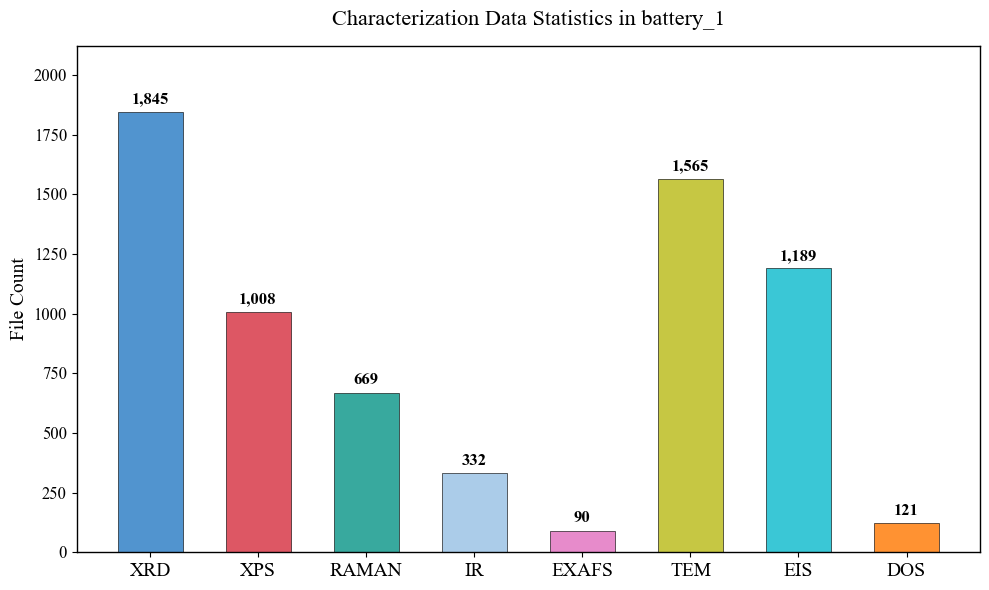

In [3]:
import os
from pathlib import Path
from collections import defaultdict

def count_characterization_files(base_path: str):
    """
    统计 base_path 下所有子文件夹中 chemical_formulas_{category}.json 文件的数量
    
    Args:
        base_path: 基础路径，如 E:\data_base\battery_1
    
    Returns:
        dict: 每个类别的文件数量统计
    """
    # 定义要统计的类别
    categories = ['xrd', 'xps', 'raman', 'ir', 'exafs', 'tem', 'eis', 'dos']
    
    # 初始化计数器
    category_counts = defaultdict(int)
    folder_count = 0
    
    base_path = Path(base_path)
    
    if not base_path.exists():
        print(f"❌ 路径不存在: {base_path}")
        return None
    
    print(f"📂 正在扫描目录: {base_path}")
    print("-" * 60)
    
    # 遍历所有子文件夹
    for folder in base_path.iterdir():
        if folder.is_dir():
            folder_count += 1
            
            # 在每个子文件夹中查找 chemical_formulas_{category}.json 文件
            for category in categories:
                json_file = folder / f"chemical_formulas_{category}.json"
                if json_file.exists():
                    category_counts[category] += 1
    
    # 打印统计结果
    print(f"\n📊 统计结果:")
    print(f"   - 扫描的文件夹总数: {folder_count}")
    print("-" * 60)
    print(f"{'类别':<12} {'数量':>10}")
    print("-" * 60)
    
    total = 0
    for category in categories:
        count = category_counts[category]
        total += count
        print(f"{category.upper():<12} {count:>10}")
    
    print("-" * 60)
    print(f"{'总计':<12} {total:>10}")
    print("=" * 60)
    
    return dict(category_counts)

# 执行统计
# base_path = r"E:\数据库项目\data_base\battery_1"
results = []
for i in range(1,3):
    result = count_characterization_files(rf"E:\数据库项目\data_base\battery_{i}")
    results.append(result)
# result = count_characterization_files(base_path)

# 可视化统计结果
if results:
    import matplotlib.pyplot as plt
    import numpy as np
    
    # 设置字体
    try:
        plt.rcParams['font.family'] = 'Times New Roman'
    except:
        plt.rcParams['font.family'] = 'serif'
    
    # 准备数据
    categories = ['XRD', 'XPS', 'RAMAN', 'IR', 'EXAFS', 'TEM', 'EIS', 'DOS']
    counts = [sum(r.get(cat.lower(), 0) for r in results) for cat in categories]
    
    # 颜色设置
    colors = ['#3381C7', '#D73949', '#159A8D', '#9DC3E6', '#E377C2', '#BCBD22', '#17BECF', '#FF7F0E']
    
    # 创建柱状图
    fig, ax = plt.subplots(figsize=(10, 6))
    
    x = np.arange(len(categories))
    bars = ax.bar(x, counts, width=0.6, color=colors, alpha=0.85, edgecolor='black', linewidth=0.5)
    
    # 在柱子上方添加数值标签
    for bar, count in zip(bars, counts):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, height + max(counts) * 0.01,
                f'{count:,}', ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    # 样式设置
    ax.set_xticks(x)
    ax.set_xticklabels(categories, fontsize=14)
    ax.set_ylabel('File Count', fontsize=14)
    ax.set_title('Characterization Data Statistics in battery_1', fontsize=16, pad=15)
    
    # Y轴设置
    ax.tick_params(axis='y', labelsize=12)
    ax.set_ylim(0, max(counts) * 1.15)
    
    # 边框设置
    for spine in ['top', 'bottom', 'left', 'right']:
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_linewidth(1.0)
    
    plt.tight_layout()
    
    # 保存图表
    output_filename = 'battery_1_statistics.png'
    plt.savefig(output_filename, dpi=300, bbox_inches='tight')
    print(f"\n✅ 柱状图已保存为: {output_filename}")
    
    plt.show()
